# HemoLink: Emergency Blood Distribution
## Capacitated Transportation with a Prohibited Lane

**Operations Research project | Complete, self-contained notebook**

HemoLink allocates a single, prequalified blood component from four blood banks to six hospitals during one delivery round. It minimizes transport cost while satisfying supply, demand, a prohibited service lane, and a cold-box capacity limit. The analysis compares Northwest Corner, Least Cost, and Vogel's Approximation, then implements bounded MODI with auditable closed-loop calculations.

**Data provenance:** Every quantity, tariff, capacity, hospital label, and shortage penalty in this case is synthetic. The case demonstrates optimization methods; it does not contain real hospital records or clinical demand estimates. Its medical motivation is grounded in WHO blood cold-chain guidance [1].

**Deliverables included:** mathematical formulation, all VAM penalties, initial allocations and costs, actual MODI iterations, final reduced costs, independent LP verification, scenario shipment tables, both dummy cases, managerial memo, presentation points, and executable validation.


### Reading map

1. [Requirements and assumptions](#requirements-and-assumptions)
2. [Inputs and mathematical formulation](#inputs-and-mathematical-formulation)
3. [Feasibility and initial solution methods](#feasibility-and-initial-solution-methods)
4. [Bounded MODI and worked calculations](#bounded-modi-and-worked-calculations)
5. [Results and visual comparisons](#results-and-visual-comparisons)
6. [Scenarios and dummy balancing](#scenarios-and-dummy-balancing)
7. [Sensitivity and constraint effects](#sensitivity-and-constraint-effects)
8. [Managerial memo and presentation points](#managerial-memo-and-presentation-points)
9. [Validation and full audit trails](#validation-and-full-audit-trails)
10. [References and discussion preparation](#references-and-discussion-preparation)


## Requirements and assumptions

| Course requirement | HemoLink implementation |
|---|---|
| Medical application | Blood distribution during a constrained cold-chain delivery round |
| Decision variables, objective, supply, demand, nonnegativity | Explicit transportation LP and numerical equations |
| Prohibited lane | B1 to H4 has upper bound zero, even though its illustrative tariff is the lowest |
| Additional capacity constraint | B3 to H4 can carry at most 18 units in the base round |
| Initial feasible solutions | NWC, LCM, and VAM, with declared tie rules and a residual-feasibility guard |
| VAM penalties | Row and column penalties at every step, including the first step by hand |
| MODI / u-v calculations | Potentials, reduced costs, signed loops, theta, basis changes, bound flips |
| Final optimality evidence | Every cell's status and sign condition, primal audit, dual gap, LP agreement |
| What-if analysis | Cost spike, demand shift, shortage, capacity expansion, vehicle failure, surplus |
| Unbalanced tables | Dummy source for unmet demand; dummy destination for retained inventory |
| Managerial interpretation | Computed insights, a memo of at most 200 words, and presentation bullets |

The modeling sequence follows the uploaded OR lectures and examples. Lecture 5's hospital supply exercise supplies the structure for the two additional constraints and the cost/demand scenarios. This project uses its own medical case and data rather than copying its numerical case.

**Assumptions**

- One blood component and one specified blood group are modeled. Eligibility for the requests has already been established; blood-group matching is not an optimization decision here.
- Supply is usable stock allocated to this round. Demand is an assumed request for the same product and period.
- Tariffs are illustrative EGP per unit transported, excluding the medical product's value. Costs are linear, with no fixed vehicle activation charge.
- B1-H4 has no qualified cold-chain transport service available in this round. The quoted tariff remains visible to demonstrate that a cheap lane can still be prohibited.
- B3-H4 has 18 unit-slots in qualified transport containers. This lane capacity is additional to blood-bank supply.
- Other lanes are assumed qualified. Their eligibility is input data; no temperature threshold or expiry model is invented.
- Each lane is a specified bank-to-hospital delivery service. Multi-stop vehicle routing, stock aging, and multiple products are extensions outside this single-round model.


### Run instructions

Open this file in Jupyter or VS Code, select a Python 3.10+ kernel, and choose **Run All**. All inputs are embedded below. No file download, API key, or network call is needed during execution.

If the environment needs dependencies, install them once in that environment:

```bash
python -m pip install numpy pandas scipy matplotlib ipykernel
```

The delivered file includes computed outputs. Timings are informational and depend on the machine; they are not used to claim a speed ranking on this small instance. Exporting local CSV files is optional and disabled by default.


In [1]:
from dataclasses import dataclass, replace
from collections import deque
from time import perf_counter
from pathlib import Path
import platform
import json
import math
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import linprog
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

try:
    from IPython.display import display, Markdown, HTML
except ImportError:
    class Markdown(str):
        def _repr_markdown_(self):
            return str(self)
    class HTML(str):
        def _repr_html_(self):
            return str(self)
    def display(*objects):
        for obj in objects:
            print(obj.to_string() if isinstance(obj, pd.DataFrame) else obj)

TOL = 1e-8
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 3)
plt.rcParams.update({
    'figure.dpi': 125, 'font.size': 10, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titleweight': 'bold',
    'axes.labelcolor': '#334155', 'text.color': '#0f172a',
    'axes.prop_cycle': plt.cycler(color=['#b91c1c', '#0369a1', '#0f766e', '#a16207'])
})


In [2]:
display(pd.DataFrame({
    'Component': ['Python', 'NumPy', 'pandas', 'SciPy', 'Matplotlib'],
    'Version': [platform.python_version(), np.__version__, pd.__version__, scipy.__version__, matplotlib.__version__]
}))


,Component,Version
0,Python,3.12.14
1,NumPy,2.3.5
2,pandas,2.2.3
3,SciPy,1.17.0
4,Matplotlib,3.10.8


## Inputs and mathematical formulation

The planning horizon is one delivery round. B1-B4 denote hypothetical blood banks; H1-H6 denote hypothetical hospital request locations. Labels such as Trauma and Maternity describe the case narrative and do not establish real clinical priorities.

| Input | Units | Meaning |
|---|---|---|
| `cost[i,j]` | EGP / blood unit | Linear delivery cost on lane i-j |
| `supply[i]` | Blood units / round | Available supply at blood bank i |
| `demand[j]` | Blood units / round | Required units at hospital j |
| `upper[i,j]` | Blood units / round | Lane limit; zero prohibits a lane, infinity means no additional lane cap |
| `x[i,j]` | Blood units / round | Quantity allocated to lane i-j |

The data class validates dimensions, finite costs, nonnegative quantities, and integer blood-unit supplies/capacities. A prohibition is encoded by a bound of zero rather than by an arbitrary large cost.


In [3]:
@dataclass
class TransportProblem:
    name: str
    cost: np.ndarray
    supply: np.ndarray
    demand: np.ndarray
    upper: np.ndarray
    sources: list
    hospitals: list
    real_rows: int = None
    real_cols: int = None
    dummy_kind: str = None

    def __post_init__(self):
        self.cost = np.array(self.cost, dtype=float, copy=True)
        self.supply = np.array(self.supply, dtype=float, copy=True)
        self.demand = np.array(self.demand, dtype=float, copy=True)
        self.upper = np.array(self.upper, dtype=float, copy=True)
        self.sources = list(self.sources)
        self.hospitals = list(self.hospitals)
        m, n = self.cost.shape
        if self.supply.shape != (m,) or self.demand.shape != (n,):
            raise ValueError('Supply/demand dimensions do not match the cost matrix.')
        if self.upper.shape != (m, n):
            raise ValueError('The upper-bound matrix has the wrong shape.')
        if len(self.sources) != m or len(self.hospitals) != n:
            raise ValueError('Node labels do not match the matrix.')
        if not np.isfinite(self.cost).all():
            raise ValueError('Costs must be finite; represent prohibitions by upper=0.')
        for a in (self.supply, self.demand):
            if not np.isfinite(a).all() or np.any(a < 0):
                raise ValueError('Supply/demand must be finite and nonnegative.')
            if not np.allclose(a, np.rint(a), atol=TOL, rtol=0):
                raise ValueError('Blood-unit quantities must be integers.')
        if np.isnan(self.upper).any() or np.any(self.upper < 0):
            raise ValueError('Upper bounds must be nonnegative or positive infinity.')
        finite = self.upper[np.isfinite(self.upper)]
        if not np.allclose(finite, np.rint(finite), atol=TOL, rtol=0):
            raise ValueError('Finite blood-unit capacities must be integers.')
        self.real_rows = m if self.real_rows is None else self.real_rows
        self.real_cols = n if self.real_cols is None else self.real_cols

    @property
    def shape(self):
        return self.cost.shape

    def copy(self, name=None, **changes):
        return replace(self, name=name or self.name, **changes)


def total_cost(problem, allocation):
    return float(np.sum(problem.cost * allocation))


def balance_problem(problem, shortage_penalty=500.0, shortage_upper=None):
    gap = int(round(problem.supply.sum() - problem.demand.sum()))
    if gap == 0:
        return problem.copy()
    m, n = problem.shape
    if gap > 0:
        return problem.copy(
            name=problem.name + ' | surplus balanced',
            cost=np.column_stack([problem.cost, np.zeros(m)]),
            upper=np.column_stack([problem.upper, np.full(m, np.inf)]),
            demand=np.r_[problem.demand, gap],
            hospitals=problem.hospitals + ['DUMMY: retained inventory'],
            dummy_kind='surplus'
        )
    penalties = np.broadcast_to(np.asarray(shortage_penalty, float), (n,)).copy()
    if not np.isfinite(penalties).all() or np.any(penalties < 0):
        raise ValueError('Shortage penalties must be finite and nonnegative.')
    dummy_upper = np.full(n, np.inf) if shortage_upper is None else np.asarray(shortage_upper, float)
    return problem.copy(
        name=problem.name + ' | shortage balanced',
        cost=np.vstack([problem.cost, penalties]),
        upper=np.vstack([problem.upper, dummy_upper]),
        supply=np.r_[problem.supply, -gap],
        sources=problem.sources + ['DUMMY: unmet demand'],
        dummy_kind='shortage'
    )


def matrix_frame(problem, values, margins=False):
    frame = pd.DataFrame(values, index=problem.sources, columns=problem.hospitals)
    if margins:
        frame['Supply'] = problem.supply
        frame.loc['Demand'] = list(problem.demand) + [problem.supply.sum()]
    return frame


def allocation_audit(problem, allocation):
    x = np.asarray(allocation, float)
    rows = []
    for name, observed, expected in zip(problem.sources, x.sum(axis=1), problem.supply):
        rows.append((f'Supply: {name}', observed, expected, abs(observed-expected) < TOL))
    for name, observed, expected in zip(problem.hospitals, x.sum(axis=0), problem.demand):
        rows.append((f'Demand: {name}', observed, expected, abs(observed-expected) < TOL))
    finite = np.isfinite(problem.upper)
    cap_excess = float(np.max(np.r_[0.0, (x-problem.upper)[finite]]))
    forbidden_flow = float(x[problem.upper <= TOL].sum())
    rows.extend([
        ('Nonnegativity: minimum allocation', float(x.min()), 0.0, bool(x.min() >= -TOL)),
        ('Prohibited/fixed lanes: total flow', forbidden_flow, 0.0, abs(forbidden_flow) < TOL),
        ('Capacity: maximum excess', cap_excess, 0.0, cap_excess < TOL),
        ('Integrality: maximum distance to integer', float(np.max(abs(x-np.rint(x)))), 0.0,
         bool(np.allclose(x, np.rint(x), atol=TOL, rtol=0)))
    ])
    return pd.DataFrame(rows, columns=['Constraint', 'Observed', 'Target / limit', 'Passed'])


def assert_feasible(problem, allocation):
    audit = allocation_audit(problem, allocation)
    if not audit['Passed'].all():
        raise AssertionError(audit.loc[~audit['Passed']].to_string(index=False))
    return True


### Editable case inputs

Change this cell to study a new case. All result tables and plots are calculated from these arrays. In the base case, the total supply and demand are both 190 blood units. The tariff of 1 on B1-H4 is hypothetical and cannot authorize using that lane.


In [4]:
SOURCES = ['B1 Central', 'B2 North', 'B3 East', 'B4 South']
HOSPITALS = ['H1 Trauma', 'H2 Maternity', 'H3 Oncology', 'H4 Surgery', 'H5 Pediatric', 'H6 Regional']
COST = np.array([
    [4, 6, 9, 1, 12, 10],
    [7, 4, 8, 9, 6, 11],
    [9, 8, 5, 3, 7, 6],
    [11, 9, 4, 8, 5, 7]
], dtype=float)
SUPPLY = np.array([45, 55, 50, 40])
DEMAND = np.array([30, 35, 40, 25, 30, 30])
UPPER = np.full(COST.shape, np.inf)
UPPER[0, 3] = 0
UPPER[2, 3] = 18
BASE = TransportProblem('Base', COST, SUPPLY, DEMAND, UPPER, SOURCES, HOSPITALS)


In [5]:
display(Markdown('**Cost table, EGP per unit, with supply and demand**'))
display(matrix_frame(BASE, BASE.cost, margins=True))
capacity_display = matrix_frame(BASE, BASE.upper).map(
    lambda value: 'PROHIBITED' if value==0 else 'No extra lane cap' if np.isinf(value) else f'{value:g} units'
)
display(Markdown('**Lane eligibility and capacities**'))
display(capacity_display)
display(pd.DataFrame({
    'Metric': ['Total supply', 'Total demand', 'Difference', 'Number of banks', 'Number of hospitals'],
    'Value': [BASE.supply.sum(), BASE.demand.sum(), BASE.supply.sum()-BASE.demand.sum(), *BASE.shape]
}))


**Cost table, EGP per unit, with supply and demand**

,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,Supply
B1 Central,4.0,6.0,9.0,1.0,12.0,10.0,45.0
B2 North,7.0,4.0,8.0,9.0,6.0,11.0,55.0
B3 East,9.0,8.0,5.0,3.0,7.0,6.0,50.0
B4 South,11.0,9.0,4.0,8.0,5.0,7.0,40.0
Demand,30.0,35.0,40.0,25.0,30.0,30.0,190.0


**Lane eligibility and capacities**

,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional
B1 Central,No extra lane cap,No extra lane cap,No extra lane cap,PROHIBITED,No extra lane cap,No extra lane cap
B2 North,No extra lane cap,No extra lane cap,No extra lane cap,No extra lane cap,No extra lane cap,No extra lane cap
B3 East,No extra lane cap,No extra lane cap,No extra lane cap,18 units,No extra lane cap,No extra lane cap
B4 South,No extra lane cap,No extra lane cap,No extra lane cap,No extra lane cap,No extra lane cap,No extra lane cap


,Metric,Value
0,Total supply,190.0
1,Total demand,190.0
2,Difference,0.0
3,Number of banks,4.0
4,Number of hospitals,6.0


### General mathematical model

Let $I=\{1,\ldots,4\}$ and $J=\{1,\ldots,6\}$. The decision variable $x_{ij}$ is the number of eligible blood units allocated from bank $i$ to hospital $j$.

$$\min Z=\sum_{i\in I}\sum_{j\in J}c_{ij}x_{ij}$$

subject to

$$\sum_j x_{ij}=s_i\quad\forall i,\qquad \sum_i x_{ij}=d_j\quad\forall j,$$
$$x_{ij}\ge 0,\qquad x_{14}=0,\qquad x_{34}\le18.$$

All supplies, demands, and finite capacities are integers. This bounded network transportation LP has integral optimal vertices, so an integer optimum can be obtained without adding binary vehicle variables. The code also checks that allocations are integral.

For the balanced table, the ten supply/demand equations contain one redundancy. With a connected admissible network, the transportation basis has $m+n-1=9$ arcs. An arc fixed at its upper bound may be **nonbasic and positive**, so the number of occupied cells can exceed nine.


In [6]:
objective_rows = []
for i in range(BASE.shape[0]):
    objective_rows.append(' + '.join(f'{BASE.cost[i,j]:g}x_{{{i+1},{j+1}}}' for j in range(BASE.shape[1])))
display(Markdown('**Expanded objective**\n\n$$\\begin{aligned}\\min Z={}&'
                 + r'\\ &+'.join(objective_rows)+r'\end{aligned}$$'))
supply_equations = [r' + '.join(f'x_{{{i+1},{j+1}}}' for j in range(BASE.shape[1]))
                    + f'={BASE.supply[i]:g}' for i in range(BASE.shape[0])]
demand_equations = [r' + '.join(f'x_{{{i+1},{j+1}}}' for i in range(BASE.shape[0]))
                    + f'={BASE.demand[j]:g}' for j in range(BASE.shape[1])]
display(Markdown('**Supply equations**\n\n$$\\begin{aligned}'
                 + r'\\'.join(supply_equations)+r'\end{aligned}$$'))
display(Markdown('**Demand equations**\n\n$$\\begin{aligned}'
                 + r'\\'.join(demand_equations)+r'\end{aligned}$$'))


**Expanded objective**

$$\begin{aligned}\min Z={}&4x_{1,1} + 6x_{1,2} + 9x_{1,3} + 1x_{1,4} + 12x_{1,5} + 10x_{1,6}\\ &+7x_{2,1} + 4x_{2,2} + 8x_{2,3} + 9x_{2,4} + 6x_{2,5} + 11x_{2,6}\\ &+9x_{3,1} + 8x_{3,2} + 5x_{3,3} + 3x_{3,4} + 7x_{3,5} + 6x_{3,6}\\ &+11x_{4,1} + 9x_{4,2} + 4x_{4,3} + 8x_{4,4} + 5x_{4,5} + 7x_{4,6}\end{aligned}$$

**Supply equations**

$$\begin{aligned}x_{1,1} + x_{1,2} + x_{1,3} + x_{1,4} + x_{1,5} + x_{1,6}=45\\x_{2,1} + x_{2,2} + x_{2,3} + x_{2,4} + x_{2,5} + x_{2,6}=55\\x_{3,1} + x_{3,2} + x_{3,3} + x_{3,4} + x_{3,5} + x_{3,6}=50\\x_{4,1} + x_{4,2} + x_{4,3} + x_{4,4} + x_{4,5} + x_{4,6}=40\end{aligned}$$

**Demand equations**

$$\begin{aligned}x_{1,1} + x_{2,1} + x_{3,1} + x_{4,1}=30\\x_{1,2} + x_{2,2} + x_{3,2} + x_{4,2}=35\\x_{1,3} + x_{2,3} + x_{3,3} + x_{4,3}=40\\x_{1,4} + x_{2,4} + x_{3,4} + x_{4,4}=25\\x_{1,5} + x_{2,5} + x_{3,5} + x_{4,5}=30\\x_{1,6} + x_{2,6} + x_{3,6} + x_{4,6}=30\end{aligned}$$

## Feasibility and initial solution methods

### Feasibility is checked before cost minimization

Equal total supply and demand are necessary for a balanced table, but prohibited lanes and capacity cuts can still make it infeasible. The implementation constructs a maximum-flow network: source to banks, banks to hospitals with lane capacities, and hospitals to sink. Full flow equal to total demand certifies that every request can be assigned under the stated constraints.

This feasibility check is implemented directly with augmenting paths. It does not use transport costs and does not call the LP cost optimizer.


In [7]:
def transport_feasibility(supply, demand, upper):
    s, d, u = np.asarray(supply, float), np.asarray(demand, float), np.asarray(upper, float)
    m, n = u.shape
    required = float(d.sum())
    if abs(s.sum()-required) > TOL:
        return {'feasible': False, 'reason': 'Totals differ; balance the table first.',
                'max_flow': None, 'required': required}
    source, sink = m+n, m+n+1
    cap = np.zeros((m+n+2, m+n+2))
    cap[source, :m] = s
    cap[:m, m:m+n] = np.minimum(u, required)
    cap[m:m+n, sink] = d
    residual = cap.copy()
    value = 0.0
    while True:
        parent = np.full(m+n+2, -1, dtype=int)
        parent[source] = source
        queue = deque([source])
        while queue and parent[sink] < 0:
            a = queue.popleft()
            for b in np.flatnonzero(residual[a] > TOL):
                if parent[b] < 0:
                    parent[b] = a
                    queue.append(int(b))
                    if b == sink:
                        break
        if parent[sink] < 0:
            break
        q, b = np.inf, sink
        while b != source:
            a = parent[b]
            q = min(q, residual[a, b])
            b = a
        b = sink
        while b != source:
            a = parent[b]
            residual[a, b] -= q
            residual[b, a] += q
            b = a
        value += q
    reachable = {source}
    queue = deque([source])
    while queue:
        a = queue.popleft()
        for b in np.flatnonzero(residual[a] > TOL):
            if int(b) not in reachable:
                reachable.add(int(b))
                queue.append(int(b))
    x = cap[:m, m:m+n] - residual[:m, m:m+n]
    return {
        'feasible': abs(value-required) < TOL,
        'reason': 'All margins can be satisfied.' if abs(value-required) < TOL else 'A route/capacity cut prevents full coverage.',
        'flow': x, 'max_flow': value, 'required': required,
        'unmet': d-x.sum(axis=0), 'unsent': s-x.sum(axis=1),
        'cut_rows': [i for i in range(m) if i in reachable],
        'cut_cols': [j for j in range(n) if m+j in reachable]
    }


def largest_safe_allocation(supply, demand, residual_upper, i, j, proposed):
    def feasible_after(q):
        s, d, u = supply.copy(), demand.copy(), residual_upper.copy()
        s[i] -= q
        d[j] -= q
        u[i, j] -= q
        return transport_feasibility(s, d, u)['feasible']
    if feasible_after(proposed):
        return int(round(proposed)), False
    witness = transport_feasibility(supply, demand, residual_upper)
    if not witness['feasible']:
        raise ValueError('The remaining transportation table is infeasible.')
    low = int(round(witness['flow'][i, j]))
    high = int(round(proposed))-1
    while low < high:
        middle = (low+high+1)//2
        if feasible_after(middle):
            low = middle
        else:
            high = middle-1
    return low, True


In [8]:
base_feasibility = transport_feasibility(BASE.supply, BASE.demand, BASE.upper)
display(pd.DataFrame([{
    'Total required': base_feasibility['required'],
    'Maximum deliverable under bounds': base_feasibility['max_flow'],
    'Feasible': base_feasibility['feasible'],
    'Reason': base_feasibility['reason']
}]))
assert base_feasibility['feasible']


,Total required,Maximum deliverable under bounds,Feasible,Reason
0,190.0,190.0,True,All margins can be satisfied.


### NWC, LCM, VAM, and declared tie rules

| Method | Selection rule | Tie handling | Guarantee before MODI |
|---|---|---|---|
| NWC | First eligible cell in row-major order | Source then hospital index | Feasibility with the guard; no cost guarantee |
| LCM | Lowest eligible unit cost | Larger immediate allocation, then indices | Feasibility with the guard; no optimality guarantee |
| VAM | Largest row/column penalty; cheapest cell in that line | Lower cell cost, larger allocation, row before column, indices | Feasibility with the guard; no optimality guarantee |

For at least two eligible costs, VAM uses

$$p=\text{second-lowest eligible cost}-\text{lowest eligible cost}.$$

A line with one eligible cell receives infinite priority in this implementation. Prohibited, exhausted, and full-capacity lanes are excluded. For a chosen lane, the first quantity proposed is

$$q_{\max}=\min\{s_i^{\mathrm{remaining}},d_j^{\mathrm{remaining}},U_{ij}-x_{ij}\}.$$

**Extension for constrained tables:** a residual maximum-flow check tests the proposed allocation. If it would make the remaining requests impossible to satisfy, an integer search finds the largest smaller quantity that preserves feasibility. A feasible witness supplies the lower search endpoint. A lane whose maximum feasible quantity is zero is skipped. Every intervention is logged.

Therefore the comparisons below are explicitly **feasibility-aware NWC/LCM/VAM variants**. This extension matters because ordinary greedy allocation can get stuck when routes are prohibited or capped. When the guard does not intervene, the declared textbook selection/allocation rule is unchanged. MODI and the LP benchmark perform the cost optimization afterward.


In [9]:
def select_initial_cell(problem, s, d, residual_upper, blocked, method):
    eligible = (s[:, None] > TOL) & (d[None, :] > TOL) & (residual_upper > TOL) & ~blocked
    cells = [tuple(map(int, e)) for e in np.argwhere(eligible)]
    if not cells:
        raise ValueError('No eligible lane remains.')
    room = lambda i, j: min(s[i], d[j], residual_upper[i, j])
    if method == 'NWC':
        i, j = min(cells)
        return i, j, 'Northwest eligible cell', [], []
    if method == 'LCM':
        i, j = min(cells, key=lambda e: (problem.cost[e], -room(*e), e[0], e[1]))
        return i, j, 'Lowest eligible unit cost', [], []
    if method != 'VAM':
        raise ValueError('Choose NWC, LCM, or VAM.')
    row_penalties, column_penalties, candidates = [], [], []
    for axis in (0, 1):
        count = problem.shape[axis]
        for line in range(count):
            entries = [(i, j) for i, j in cells if (i if axis == 0 else j) == line]
            if not entries:
                continue
            values = sorted(float(problem.cost[e]) for e in entries)
            penalty = np.inf if len(values) == 1 else values[1]-values[0]
            i, j = min(entries, key=lambda e: (problem.cost[e], -room(*e), e[0], e[1]))
            label = problem.sources[line] if axis == 0 else problem.hospitals[line]
            record = {'Line': label, 'Eligible costs': values,
                      'Smallest': values[0], 'Second smallest': values[1] if len(values)>1 else np.nan,
                      'Penalty': penalty}
            (row_penalties if axis == 0 else column_penalties).append(record)
            key = (-penalty, float(problem.cost[i, j]), -room(i, j), axis, line)
            candidates.append((key, i, j, label))
    _, i, j, label = min(candidates, key=lambda entry: entry[0])
    return i, j, 'Maximum penalty: ' + label, row_penalties, column_penalties


def initial_solution(problem, method='VAM', feasibility_guard=True):
    check = transport_feasibility(problem.supply, problem.demand, problem.upper)
    if not check['feasible']:
        raise ValueError(check['reason'])
    s, d = problem.supply.copy(), problem.demand.copy()
    x = np.zeros(problem.shape)
    blocked = np.zeros(problem.shape, dtype=bool)
    history = []
    start = perf_counter()
    while s.sum() > TOL:
        if len(history) > 4*problem.cost.size:
            raise RuntimeError('Initial solution exceeded the safety iteration limit.')
        residual_upper = problem.upper-x
        i, j, reason, rp, cp = select_initial_cell(problem, s, d, residual_upper, blocked, method)
        proposed = int(round(min(s[i], d[j], residual_upper[i, j])))
        quantity, guarded = largest_safe_allocation(s, d, residual_upper, i, j, proposed) if feasibility_guard else (proposed, False)
        before = x.copy()
        s_before, d_before = s.copy(), d.copy()
        x[i, j] += quantity
        s[i] -= quantity
        d[j] -= quantity
        if quantity == 0:
            blocked[i, j] = True
        history.append({
            'step': len(history)+1, 'cell': (i, j), 'reason': reason,
            'proposed': proposed, 'quantity': quantity, 'guarded': guarded,
            'row_penalties': rp, 'column_penalties': cp,
            'supply_before': s_before, 'demand_before': d_before,
            'supply_after': s.copy(), 'demand_after': d.copy(),
            'before': before, 'after': x.copy(), 'running_cost': total_cost(problem, x)
        })
    assert_feasible(problem, x)
    return {'method': method, 'x': x, 'cost': total_cost(problem, x),
            'history': history, 'guard_events': sum(h['guarded'] for h in history),
            'elapsed_ms': 1000*(perf_counter()-start)}


In [10]:
initial_base = {method: initial_solution(BASE, method) for method in ('NWC', 'LCM', 'VAM')}
display(pd.DataFrame([
    {'Method': method, 'Initial cost EGP': result['cost'],
     'Committed allocations': sum(h['quantity']>0 for h in result['history']),
     'Guard events': result['guard_events'], 'Feasible': assert_feasible(BASE,result['x'])}
    for method,result in initial_base.items()
]))
for method, result in initial_base.items():
    display(Markdown(f'**{method}: initial allocation**'))
    display(matrix_frame(BASE, result['x'], margins=True))


,Method,Initial cost EGP,Committed allocations,Guard events,Feasible
0,NWC,1119.0,10,0,True
1,LCM,989.0,9,2,True
2,VAM,927.0,10,2,True


**NWC: initial allocation**

,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,Supply
B1 Central,30.0,15.0,0.0,0.0,0.0,0.0,45.0
B2 North,0.0,20.0,35.0,0.0,0.0,0.0,55.0
B3 East,0.0,0.0,5.0,18.0,27.0,0.0,50.0
B4 South,0.0,0.0,0.0,7.0,3.0,30.0,40.0
Demand,30.0,35.0,40.0,25.0,30.0,30.0,190.0


**LCM: initial allocation**

,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,Supply
B1 Central,30.0,0.0,0.0,0.0,15.0,0.0,45.0
B2 North,0.0,35.0,0.0,7.0,13.0,0.0,55.0
B3 East,0.0,0.0,0.0,18.0,2.0,30.0,50.0
B4 South,0.0,0.0,40.0,0.0,0.0,0.0,40.0
Demand,30.0,35.0,40.0,25.0,30.0,30.0,190.0


**VAM: initial allocation**

,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,Supply
B1 Central,30.0,15.0,0.0,0.0,0.0,0.0,45.0
B2 North,0.0,20.0,0.0,5.0,30.0,0.0,55.0
B3 East,0.0,0.0,2.0,18.0,0.0,30.0,50.0
B4 South,0.0,0.0,38.0,2.0,0.0,0.0,40.0
Demand,30.0,35.0,40.0,25.0,30.0,30.0,190.0


### VAM first step: penalties and allocation by hand

The two penalty tables below are calculated from the eligible base lanes. B1-H4 does not enter any penalty calculation. The B3-H4 cap affects the quantity allocated; its tariff remains eligible until that cap is full.


In [11]:
first_vam = initial_base['VAM']['history'][0]
display(pd.DataFrame(first_vam['row_penalties']))
display(pd.DataFrame(first_vam['column_penalties']))
i,j = first_vam['cell']
display(Markdown(
    f'The selected lane is **{BASE.sources[i]} to {BASE.hospitals[j]}**. '
    f'The eligible H4 costs are 3, 8, and 9, giving a penalty of $8-3=5$. '
    f'Its unit cost is {BASE.cost[i,j]:g} EGP.\n\n'
    f'$$q=\\min({first_vam["supply_before"][i]:g},'
    f'{first_vam["demand_before"][j]:g},{BASE.upper[i,j]:g})={first_vam["quantity"]:g}.$$\n\n'
    f'Remaining bank supply: {first_vam["supply_after"][i]:g}. '
    f'Remaining hospital demand: {first_vam["demand_after"][j]:g}. '
    f'Initial cost contribution: ${first_vam["quantity"]:g}\\times{BASE.cost[i,j]:g}'
    f'={first_vam["running_cost"]:g}$ EGP.'
))


,Line,Eligible costs,Smallest,Second smallest,Penalty
0,B1 Central,"[4.0, 6.0, 9.0, 10.0, 12.0]",4.0,6.0,2.0
1,B2 North,"[4.0, 6.0, 7.0, 8.0, 9.0, 11.0]",4.0,6.0,2.0
2,B3 East,"[3.0, 5.0, 6.0, 7.0, 8.0, 9.0]",3.0,5.0,2.0
3,B4 South,"[4.0, 5.0, 7.0, 8.0, 9.0, 11.0]",4.0,5.0,1.0


,Line,Eligible costs,Smallest,Second smallest,Penalty
0,H1 Trauma,"[4.0, 7.0, 9.0, 11.0]",4.0,7.0,3.0
1,H2 Maternity,"[4.0, 6.0, 8.0, 9.0]",4.0,6.0,2.0
2,H3 Oncology,"[4.0, 5.0, 8.0, 9.0]",4.0,5.0,1.0
3,H4 Surgery,"[3.0, 8.0, 9.0]",3.0,8.0,5.0
4,H5 Pediatric,"[5.0, 6.0, 7.0, 12.0]",5.0,6.0,1.0
5,H6 Regional,"[6.0, 7.0, 10.0, 11.0]",6.0,7.0,1.0


The selected lane is **B3 East to H4 Surgery**. The eligible H4 costs are 3, 8, and 9, giving a penalty of $8-3=5$. Its unit cost is 3 EGP.

$$q=\min(50,25,18)=18.$$

Remaining bank supply: 32. Remaining hospital demand: 7. Initial cost contribution: $18\times3=54$ EGP.

### Full initial-allocation ledger

The ledger includes zero-quantity skip events, so a step count and an allocation count may differ. A skipped lane remains physically allowed; it simply cannot receive additional committed flow in the residual table without blocking another request. Expand the detailed VAM steps in the audit appendix to see every recalculated row and column penalty.


In [12]:
def initial_history_table(problem, result):
    rows = []
    for h in result['history']:
        i, j = h['cell']
        rows.append([h['step'], problem.sources[i], problem.hospitals[j],
                     problem.cost[i, j], h['proposed'], h['quantity'],
                     h['guarded'], h['supply_after'][i], h['demand_after'][j], h['running_cost']])
    return pd.DataFrame(rows, columns=['Step', 'Source', 'Hospital', 'Unit cost',
                                      'Proposed units', 'Committed units', 'Guard used',
                                      'Source left', 'Hospital left', 'Running cost'])


In [13]:
for method,result in initial_base.items():
    display(Markdown(f'**{method} ledger**'))
    display(initial_history_table(BASE,result))


**NWC ledger**

,Step,Source,Hospital,Unit cost,Proposed units,Committed units,Guard used,Source left,Hospital left,Running cost
0,1,B1 Central,H1 Trauma,4.0,30,30,False,15.0,0.0,120.0
1,2,B1 Central,H2 Maternity,6.0,15,15,False,0.0,20.0,210.0
2,3,B2 North,H2 Maternity,4.0,20,20,False,35.0,0.0,290.0
3,4,B2 North,H3 Oncology,8.0,35,35,False,0.0,5.0,570.0
4,5,B3 East,H3 Oncology,5.0,5,5,False,45.0,0.0,595.0
5,6,B3 East,H4 Surgery,3.0,18,18,False,27.0,7.0,649.0
6,7,B3 East,H5 Pediatric,7.0,27,27,False,0.0,3.0,838.0
7,8,B4 South,H4 Surgery,8.0,7,7,False,33.0,0.0,894.0
8,9,B4 South,H5 Pediatric,5.0,3,3,False,30.0,0.0,909.0
9,10,B4 South,H6 Regional,7.0,30,30,False,0.0,0.0,1119.0


**LCM ledger**

,Step,Source,Hospital,Unit cost,Proposed units,Committed units,Guard used,Source left,Hospital left,Running cost
0,1,B3 East,H4 Surgery,3.0,18,18,False,32.0,7.0,54.0
1,2,B4 South,H3 Oncology,4.0,40,40,False,0.0,0.0,214.0
2,3,B2 North,H2 Maternity,4.0,35,35,False,20.0,0.0,354.0
3,4,B1 Central,H1 Trauma,4.0,30,30,False,15.0,0.0,474.0
4,5,B3 East,H6 Regional,6.0,30,30,False,2.0,0.0,654.0
5,6,B2 North,H5 Pediatric,6.0,20,13,True,7.0,17.0,732.0
6,7,B2 North,H5 Pediatric,6.0,7,0,True,7.0,17.0,732.0
7,8,B3 East,H5 Pediatric,7.0,2,2,False,0.0,15.0,746.0
8,9,B2 North,H4 Surgery,9.0,7,7,False,0.0,0.0,809.0
9,10,B1 Central,H5 Pediatric,12.0,15,15,False,0.0,0.0,989.0


**VAM ledger**

,Step,Source,Hospital,Unit cost,Proposed units,Committed units,Guard used,Source left,Hospital left,Running cost
0,1,B3 East,H4 Surgery,3.0,18,18,False,32.0,7.0,54.0
1,2,B1 Central,H1 Trauma,4.0,30,30,False,15.0,0.0,174.0
2,3,B1 Central,H2 Maternity,6.0,15,15,False,0.0,20.0,264.0
3,4,B2 North,H2 Maternity,4.0,20,20,False,35.0,0.0,344.0
4,5,B2 North,H5 Pediatric,6.0,30,30,False,5.0,0.0,524.0
5,6,B4 South,H3 Oncology,4.0,40,38,True,2.0,2.0,676.0
6,7,B4 South,H3 Oncology,4.0,2,0,True,2.0,2.0,676.0
7,8,B3 East,H3 Oncology,5.0,2,2,False,30.0,0.0,686.0
8,9,B3 East,H6 Regional,6.0,30,30,False,0.0,0.0,866.0
9,10,B4 South,H4 Surgery,8.0,2,2,False,0.0,5.0,882.0


In [14]:
vam_terms = [f'{initial_base["VAM"]["x"][i,j]:g}\\times{BASE.cost[i,j]:g}'
             for i,j in np.argwhere(initial_base['VAM']['x']>TOL)]
display(Markdown('**VAM initial cost, from actual allocated quantities**\n\n'
                 '$$Z_0='+ '+'.join(vam_terms)+f'={initial_base["VAM"]["cost"]:g}\\;\\mathrm{{EGP}}.$$'))


**VAM initial cost, from actual allocated quantities**

$$Z_0=30\times4+15\times6+20\times4+5\times9+30\times6+2\times5+18\times3+30\times6+38\times4+2\times8=927\;\mathrm{EGP}.$$

### Why the feasibility guard is needed in this case

In VAM, after the early commitments, B4-H3 proposes 40 units. That would exhaust B4. H4 would still need 7 units, B1 cannot serve H4, B3-H4 is already at its cap, and B2 has only 5 units left. B4 must reserve at least 2 units for H4, so its H3 commitment can be at most $40-2=38$.

Similarly, LCM must reserve 7 units of B2 for H4 rather than committing all its remaining stock to H5. These are consequences of the model's route/capacity constraints, not arbitrary changes to the heuristics.


In [15]:
guard_examples = []
for method in ('LCM','VAM'):
    h = next(event for event in initial_base[method]['history'] if event['guarded'] and event['quantity']>0)
    i,j = h['cell']
    s,d,u = h['supply_before'].copy(), h['demand_before'].copy(), BASE.upper-h['before']
    s[i] -= h['proposed']; d[j] -= h['proposed']; u[i,j] -= h['proposed']
    rejected_check = transport_feasibility(s,d,u)
    guard_examples.append({
        'Method': method, 'Lane': f'{BASE.sources[i]} to {BASE.hospitals[j]}',
        'Greedy proposal': h['proposed'], 'Safe commitment': h['quantity'],
        'Demand remaining after rejected proposal': rejected_check['required'],
        'Deliverable after rejected proposal': rejected_check['max_flow'],
        'Residual deficit avoided': rejected_check['required']-rejected_check['max_flow']
    })
display(pd.DataFrame(guard_examples))
naive_checks = []
for method in ('NWC','LCM','VAM'):
    try:
        naive = initial_solution(BASE,method,feasibility_guard=False)
        outcome = f'Completed; cost {naive["cost"]:g} EGP'
    except (ValueError,AssertionError) as error:
        outcome = 'Did not produce a complete feasible plan: '+str(error).splitlines()[0]
    naive_checks.append({'Unguarded method': method, 'Outcome on the same base data': outcome})
display(pd.DataFrame(naive_checks))


,Method,Lane,Greedy proposal,Safe commitment,Demand remaining after rejected proposal,Deliverable after rejected proposal,Residual deficit avoided
0,LCM,B2 North to H5 Pediatric,20,13,17.0,10.0,7.0
1,VAM,B4 South to H3 Oncology,40,38,37.0,35.0,2.0


,Unguarded method,Outcome on the same base data
0,NWC,Completed; cost 1119 EGP
1,LCM,Did not produce a complete feasible plan: No e...
2,VAM,Did not produce a complete feasible plan: No e...


## Bounded MODI and worked calculations

### Potentials and reduced costs

For every **basic** cell, solve

$$u_i+v_j=c_{ij}.$$

Set one potential to zero per connected component of the admissible network. For other cells compute

$$\Delta_{ij}=c_{ij}-(u_i+v_j).$$

The upper-bound constraint changes the optimality test:

| Status | Meaning | Feasible movement | Optimal reduced-cost condition |
|---|---|---|---|
| B | Basic cell, possibly degenerate at a bound | Determined through basis loops | $\Delta=0$ |
| L | Nonbasic cell at zero | Increase allocation | $\Delta\ge0$ |
| U | Nonbasic cell at finite upper bound | Decrease allocation | $\Delta\le0$ |
| F | Fixed at zero, including prohibited lanes | No movement | Excluded from the sign test |

For an L cell, a negative delta can improve cost by increasing it. For a U cell, a positive delta can improve cost by decreasing it. Thus a negative delta on a saturated capped lane may be consistent with optimality.

This is the bounded-variable transportation simplex form of MODI. It follows residual-network optimality: no feasible residual direction may have a negative reduced cost [2]. Applying the uncapped rule to every unused or occupied cell would be incorrect here.


### Closed loops, theta, and basis bookkeeping

Add the entering arc to the basic forest to obtain its unique alternating row/column loop. Start with $+$ when increasing an L cell, or $-$ when decreasing a U cell. The maximum feasible update is

$$\theta=\min\left\{\min_{(i,j)\in\text{minus}}x_{ij},\quad
\min_{(i,j)\in\text{plus}}(U_{ij}-x_{ij})\right\}.$$

The second term enforces lane capacities. Update $x\leftarrow x+\theta$ on plus corners and $x\leftarrow x-\theta$ on minus corners. A limiting basic arc leaves the basis. If the entering arc reaches its opposite bound first, it undergoes a **bound flip**, and the basis need not change.

With entering direction $d\in\{+1,-1\}$,

$$Z_{new}-Z_{old}=\theta d\Delta_{enter}.$$

Zero-length degenerate pivots are allowed. The implementation uses most negative directional reduced cost, deterministic leaving ties, a Bland fallback if a basis state repeats, and a finite iteration guard. Degenerate basic arcs have exactly zero allocation when appropriate; no fictitious fraction of a blood unit is shipped.

If a general feasible start contains an interior cycle, an explicitly logged non-increasing cycle-elimination phase converts it into a basic feasible start. Its cost change is reported separately from heuristic cost and MODI pivots. On the main base comparisons, this preparation phase requires no cycle elimination.


In [16]:
class DisjointSet:
    def __init__(self, n):
        self.parent = list(range(n))
    def find(self, a):
        while self.parent[a] != a:
            self.parent[a] = self.parent[self.parent[a]]
            a = self.parent[a]
        return a
    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a == b:
            return False
        self.parent[b] = a
        return True


def tree_path(edges, m, n, start, end):
    adjacency = [[] for _ in range(m+n)]
    for i, j in sorted(edges):
        adjacency[i].append((m+j, (i, j)))
        adjacency[m+j].append((i, (i, j)))
    parent = {start: (None, None)}
    queue = deque([start])
    while queue and end not in parent:
        a = queue.popleft()
        for b, cell in adjacency[a]:
            if b not in parent:
                parent[b] = (a, cell)
                queue.append(b)
    if end not in parent:
        return None
    path, b = [], end
    while b != start:
        a, cell = parent[b]
        path.append(cell)
        b = a
    return path[::-1]


def interior_cycle(problem, x):
    m, n = problem.shape
    edges = [tuple(map(int, e)) for e in np.argwhere((x>TOL) & (x<problem.upper-TOL))]
    forest, dsu = set(), DisjointSet(m+n)
    for cell in edges:
        i, j = cell
        if dsu.union(i, m+j):
            forest.add(cell)
        else:
            path = tree_path(forest, m, n, m+j, i)
            return [(cell, 1)] + [(e, -1 if k%2 == 0 else 1) for k, e in enumerate(path)]
    return None


def snap_bounds(problem, x):
    x[abs(x)<TOL] = 0.0
    finite = np.isfinite(problem.upper)
    near = finite & (abs(x-np.where(finite, problem.upper, 0.0))<TOL)
    x[near] = problem.upper[near]
    return x


def prepare_basis(problem, allocation):
    x = np.array(allocation, float, copy=True)
    assert_feasible(problem, x)
    preparation = []
    for _ in range(problem.cost.size+1):
        cycle = interior_cycle(problem, x)
        if cycle is None:
            break
        slope = sum(sign*problem.cost[cell] for cell, sign in cycle)
        if slope > TOL:
            cycle = [(cell, -sign) for cell, sign in cycle]
        theta = min(problem.upper[cell]-x[cell] if sign>0 else x[cell] for cell, sign in cycle)
        before_cost = total_cost(problem, x)
        for cell, sign in cycle:
            x[cell] += sign*theta
        snap_bounds(problem, x)
        preparation.append({'theta': theta, 'loop': cycle,
                            'before_cost': before_cost, 'after_cost': total_cost(problem, x)})
    else:
        raise RuntimeError('Unable to remove interior cycles.')
    m, n = problem.shape
    dsu, allowed_dsu, basis = DisjointSet(m+n), DisjointSet(m+n), set()
    for i, j in np.argwhere(problem.upper>TOL):
        allowed_dsu.union(int(i), m+int(j))
    components = len({allowed_dsu.find(a) for a in range(m+n)})
    rank = m+n-components
    for i, j in np.argwhere((x>TOL) & (x<problem.upper-TOL)):
        cell = (int(i), int(j))
        if not dsu.union(cell[0], m+cell[1]):
            raise AssertionError('Interior allocations still contain a cycle.')
        basis.add(cell)
    for i, j in np.argwhere(problem.upper>TOL):
        cell = (int(i), int(j))
        if dsu.union(cell[0], m+cell[1]):
            basis.add(cell)
    if len(basis) != rank:
        raise AssertionError('The basis does not span the admissible network.')
    assert_feasible(problem, x)
    return x, basis, preparation, rank


def basis_potentials(problem, basis):
    m, n = problem.shape
    adjacency = [[] for _ in range(m+n)]
    for i, j in sorted(basis):
        adjacency[i].append((m+j, problem.cost[i, j]))
        adjacency[m+j].append((i, problem.cost[i, j]))
    values = np.full(m+n, np.nan)
    for root in range(m+n):
        if np.isfinite(values[root]):
            continue
        values[root] = 0.0
        queue = deque([root])
        while queue:
            a = queue.popleft()
            for b, c in adjacency[a]:
                if not np.isfinite(values[b]):
                    values[b] = c-values[a]
                    queue.append(b)
    u, v = values[:m], values[m:]
    delta = problem.cost-u[:, None]-v[None, :]
    if basis and max(abs(delta[cell]) for cell in basis)>TOL:
        raise AssertionError('Basic-cell potential equations are inconsistent.')
    return u, v, delta


def cell_status(problem, x, basis, cell):
    if problem.upper[cell] <= TOL:
        return 'F'
    if cell in basis:
        return 'B'
    if np.isfinite(problem.upper[cell]) and abs(x[cell]-problem.upper[cell])<TOL:
        return 'U'
    if abs(x[cell])<TOL:
        return 'L'
    raise AssertionError('A nonbasic variable is not at a bound.')


In [17]:
def bounded_modi(problem, initial_x, initial_basis=None, max_iterations=2000):
    start = perf_counter()
    if initial_basis is None:
        x, basis, preparation, rank = prepare_basis(problem, initial_x)
    else:
        x, basis, preparation = np.array(initial_x, float, copy=True), set(initial_basis), []
        assert_feasible(problem, x)
        _, _, _, rank = prepare_basis(problem, x)
        if len(basis) != rank or any(problem.upper[e]<=TOL for e in basis):
            raise ValueError('The supplied warm-start basis is invalid.')
        for i in range(problem.shape[0]):
            for j in range(problem.shape[1]):
                cell_status(problem, x, basis, (i, j))
    normalized_cost = total_cost(problem, x)
    iterations, seen, bland = [], set(), False
    m, n = problem.shape
    for iteration in range(max_iterations+1):
        u, v, delta = basis_potentials(problem, basis)
        state = (tuple(sorted(basis)), tuple((i, j) for i in range(m) for j in range(n)
                                            if cell_status(problem, x, basis, (i, j))=='U'))
        if state in seen:
            bland = True
        seen.add(state)
        candidates = []
        for i in range(m):
            for j in range(n):
                cell = (i, j)
                status = cell_status(problem, x, basis, cell)
                direction = 1 if status=='L' else -1 if status=='U' else 0
                directional_cost = direction*delta[cell]
                if direction and directional_cost < -TOL:
                    candidates.append((float(directional_cost), cell, direction, status))
        if not candidates:
            assert_feasible(problem, x)
            return {'x': x, 'cost': total_cost(problem, x), 'basis': set(basis),
                    'u': u, 'v': v, 'delta': delta, 'history': iterations,
                    'preparation': preparation, 'normalized_start_cost': normalized_cost,
                    'rank': rank, 'bland_used': bland,
                    'elapsed_ms': 1000*(perf_counter()-start)}
        if iteration == max_iterations:
            raise RuntimeError('MODI reached its iteration limit before proving optimality.')
        chosen = min(candidates, key=(lambda z: z[1]) if bland else (lambda z: (z[0], z[1])))
        directional_cost, entering, direction, entering_status = chosen
        path = tree_path(basis, m, n, m+entering[1], entering[0])
        if path is None:
            raise AssertionError('The entering edge has no basis path.')
        loop = [(entering, direction)] + [(cell, -direction if k%2==0 else direction)
                                          for k, cell in enumerate(path)]
        limits = [(float(problem.upper[cell]-x[cell] if sign>0 else x[cell]), cell)
                  for cell, sign in loop]
        theta = min(limit for limit, _ in limits)
        leaving = min(cell for limit, cell in limits if abs(limit-theta)<TOL)
        if theta < -TOL or not np.isfinite(theta):
            raise AssertionError('Invalid step length.')
        before, before_cost, before_basis = x.copy(), total_cost(problem, x), set(basis)
        for cell, sign in loop:
            x[cell] += sign*theta
        snap_bounds(problem, x)
        if leaving != entering:
            basis.remove(leaving)
            basis.add(entering)
        actual_change = total_cost(problem, x)-before_cost
        predicted_change = theta*directional_cost
        if abs(actual_change-predicted_change)>1e-6 or actual_change>TOL:
            raise AssertionError('The loop cost change is inconsistent.')
        assert_feasible(problem, x)
        iterations.append({
            'iteration': iteration+1, 'entering': entering, 'entering_status': entering_status,
            'direction': direction, 'leaving': leaving, 'bound_flip': leaving==entering,
            'theta': theta, 'loop': loop, 'limits': limits,
            'u': u.copy(), 'v': v.copy(), 'delta': delta.copy(), 'basis_before': before_basis,
            'before': before, 'after': x.copy(), 'cost_before': before_cost,
            'cost_after': total_cost(problem, x), 'predicted_change': predicted_change,
            'pivot_rule': 'Bland' if bland else 'Most negative directional reduced cost'
        })
    raise RuntimeError('MODI did not terminate.')


In [18]:
def optimality_certificate(problem, result):
    x, basis, delta = result['x'], result['basis'], result['delta']
    rows = []
    for i in range(problem.shape[0]):
        for j in range(problem.shape[1]):
            cell = (i, j)
            status = cell_status(problem, x, basis, cell)
            passed = {'F': True, 'B': abs(delta[cell])<TOL,
                      'L': delta[cell]>=-TOL, 'U': delta[cell]<=TOL}[status]
            rule = {'F': 'Excluded / fixed at zero', 'B': 'Delta = 0',
                    'L': 'Delta >= 0', 'U': 'Delta <= 0'}[status]
            rows.append([problem.sources[i], problem.hospitals[j], problem.cost[cell], x[cell],
                         problem.upper[cell], status, np.nan if status=='F' else delta[cell], rule, bool(passed)])
    table = pd.DataFrame(rows, columns=['Source', 'Hospital', 'Unit cost', 'Allocation', 'Upper bound',
                                        'Status', 'Delta', 'Optimality rule', 'Passed'])
    finite = np.isfinite(problem.upper)
    dual = float(result['u']@problem.supply+result['v']@problem.demand
                 + np.sum(problem.upper[finite]*np.minimum(delta[finite], 0.0)))
    gap = total_cost(problem, x)-dual
    return {'table': table, 'dual_value': dual, 'gap': gap,
            'passed': bool(table['Passed'].all() and abs(gap)<1e-6)}


def reference_lp(problem):
    m, n = problem.shape
    equality = np.zeros((m+n, m*n))
    for i in range(m):
        equality[i, i*n:(i+1)*n] = 1
    for j in range(n):
        equality[m+j, j::n] = 1
    bounds = [(0.0, None if np.isinf(u) else float(u)) for u in problem.upper.ravel()]
    result = linprog(problem.cost.ravel(), A_eq=equality,
                     b_eq=np.r_[problem.supply, problem.demand], bounds=bounds, method='highs')
    if not result.success:
        raise ValueError('Independent LP verification failed: '+result.message)
    x = result.x.reshape(m, n)
    assert_feasible(problem, x)
    return {'x': x, 'cost': float(result.fun), 'solver': result,
            'capacity_marginals': np.array(result.upper.marginals).reshape(m, n)}


def shipment_table(problem, allocation, include_dummy=True):
    rows = []
    for i, j in np.argwhere(allocation>TOL):
        dummy = i>=problem.real_rows or j>=problem.real_cols
        if not include_dummy and dummy:
            continue
        category = 'Unmet demand' if i>=problem.real_rows else 'Retained inventory' if j>=problem.real_cols else 'Delivered blood'
        rows.append([problem.sources[i], problem.hospitals[j], allocation[i, j],
                     problem.cost[i, j], allocation[i, j]*problem.cost[i, j], category])
    return pd.DataFrame(rows, columns=['Source', 'Hospital', 'Units', 'Unit cost', 'Cost contribution', 'Interpretation'])


def operational_metrics(problem, allocation):
    delivered = float(allocation[:problem.real_rows, :problem.real_cols].sum())
    shortfall = float(allocation[problem.real_rows:, :problem.real_cols].sum())
    retained = float(allocation[:problem.real_rows, problem.real_cols:].sum())
    delivery_cost = float(np.sum(allocation[:problem.real_rows, :problem.real_cols]
                                 * problem.cost[:problem.real_rows, :problem.real_cols]))
    return {'Real delivery units': delivered, 'Unmet demand units': shortfall,
            'Retained inventory units': retained, 'Transport cost EGP': delivery_cost,
            'Shortage penalty EGP': total_cost(problem, allocation)-delivery_cost,
            'Objective EGP': total_cost(problem, allocation)}


In [19]:
def repair_changed_demands(problem, previous_x):
    x = np.array(previous_x, float, copy=True)
    m, n = problem.shape
    if x.shape != problem.shape or not np.allclose(x.sum(axis=1), problem.supply, atol=TOL):
        raise ValueError('Demand repair requires unchanged source supplies and dimensions.')
    if np.any(x-problem.upper>TOL):
        raise ValueError('The old plan violates a new capacity; rebuild the initial plan.')
    history = []
    for _ in range(2*problem.cost.size):
        deviation = x.sum(axis=0)-problem.demand
        if np.max(abs(deviation))<TOL:
            assert_feasible(problem, x)
            return x, history
        found = None
        for donor in np.flatnonzero(deviation>TOL):
            for receiver in np.flatnonzero(deviation < -TOL):
                parent = {m+int(donor): None}
                queue = deque([m+int(donor)])
                target = m+int(receiver)
                while queue and target not in parent:
                    a = queue.popleft()
                    if a < m:
                        neighbors = [(m+j, (a, j), 1, problem.upper[a, j]-x[a, j])
                                     for j in range(n) if problem.upper[a, j]-x[a, j]>TOL]
                    else:
                        j = a-m
                        neighbors = [(i, (i, j), -1, x[i, j]) for i in range(m) if x[i, j]>TOL]
                    for b, cell, sign, room in neighbors:
                        if b not in parent:
                            parent[b] = (a, cell, sign, room)
                            queue.append(b)
                if target in parent:
                    path, a = [], target
                    while parent[a] is not None:
                        b, cell, sign, room = parent[a]
                        path.append((cell, sign, room))
                        a = b
                    path.reverse()
                    found = (int(donor), int(receiver), path)
                    break
            if found is not None:
                break
        if found is None:
            raise ValueError('No residual repair path exists for the changed demands.')
        donor, receiver, path = found
        quantity = min(deviation[donor], -deviation[receiver], *(r for _, _, r in path))
        for cell, sign, _ in path:
            x[cell] += sign*quantity
        snap_bounds(problem, x)
        history.append({'from_hospital': donor, 'to_hospital': receiver, 'quantity': quantity,
                        'path': [(cell, sign) for cell, sign, _ in path]})
    raise RuntimeError('Demand repair exceeded its iteration limit.')


In [20]:
def modi_history_table(problem, result):
    rows = []
    for h in result['history']:
        i, j = h['entering']
        a, b = h['leaving']
        rows.append([h['iteration'], f'{problem.sources[i]} -> {problem.hospitals[j]}',
                     h['entering_status'], h['direction'], h['theta'],
                     f'{problem.sources[a]} -> {problem.hospitals[b]}',
                     h['bound_flip'], h['cost_before'], h['cost_after'], h['predicted_change']])
    return pd.DataFrame(rows, columns=['Iteration', 'Entering lane', 'Previous status',
                                      'Direction', 'Theta', 'Leaving lane / bound flip',
                                      'Bound flip', 'Cost before', 'Cost after', 'Predicted change'])


def loop_frame(problem, step):
    limit_map = dict((cell, room) for room, cell in step['limits'])
    return pd.DataFrame([
        [problem.sources[i], problem.hospitals[j], '+' if sign>0 else '-',
         step['before'][i, j], problem.upper[i, j], limit_map[(i, j)], step['after'][i, j]]
        for (i, j), sign in step['loop']
    ], columns=['Source', 'Hospital', 'Sign', 'Before', 'Upper bound', 'Allowable step', 'After'])


def show_initial_details(problem, result):
    for h in result['history']:
        i, j = h['cell']
        body = [f'<p><b>Selection:</b> {h["reason"]}. '
                f'<b>Lane:</b> {problem.sources[i]} to {problem.hospitals[j]}. '
                f'<b>Proposed:</b> {h["proposed"]}; <b>committed:</b> {h["quantity"]}; '
                f'<b>feasibility guard:</b> {h["guarded"]}.</p>']
        for title, penalties in [('Row penalties', h['row_penalties']), ('Column penalties', h['column_penalties'])]:
            if penalties:
                body.append('<p><b>'+title+'</b></p>'+pd.DataFrame(penalties).to_html(index=False))
        remaining = pd.DataFrame({'Source': problem.sources, 'Remaining supply': h['supply_after']})
        demand = pd.DataFrame({'Hospital': problem.hospitals, 'Remaining demand': h['demand_after']})
        body.extend([remaining.to_html(index=False), demand.to_html(index=False),
                     matrix_frame(problem, h['after']).to_html(), f'<p>Running cost = {h["running_cost"]:.2f} EGP.</p>'])
        display(HTML(f'<details><summary><b>{result["method"]} step {h["step"]}: '
                     f'{problem.sources[i]} to {problem.hospitals[j]}</b></summary>'+''.join(body)+'</details>'))


def show_modi_details(problem, result, label='MODI'):
    for h in result['history']:
        potentials = pd.DataFrame({'Node': problem.sources+problem.hospitals,
                                   'Potential': np.r_[h['u'], h['v']]})
        body = [f'<p>Entering status = {h["entering_status"]}; theta = {h["theta"]:g}; '
                f'bound flip = {h["bound_flip"]}; pivot rule = {h["pivot_rule"]}.</p>',
                '<p><b>Potentials</b></p>', potentials.to_html(index=False),
                '<p><b>All reduced costs (fixed lanes are excluded from the sign test)</b></p>',
                matrix_frame(problem, h['delta']).to_html(),
                '<p><b>Closed loop and step limits</b></p>', loop_frame(problem, h).to_html(index=False),
                '<p><b>Allocation before</b></p>', matrix_frame(problem, h['before']).to_html(),
                '<p><b>Allocation after</b></p>', matrix_frame(problem, h['after']).to_html(),
                f'<p>Cost: {h["cost_before"]:.2f} to {h["cost_after"]:.2f} EGP. '
                f'Predicted change = {h["predicted_change"]:.2f} EGP.</p>']
        display(HTML(f'<details><summary><b>{label} iteration {h["iteration"]}</b></summary>'
                     + ''.join(body)+'</details>'))


def heatmap(problem, values, title, ax=None, costs=False, max_value=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4.5))
    shown = np.array(values, float, copy=True)
    shown[problem.upper<=TOL] = np.nan
    cmap = plt.get_cmap('YlOrRd').copy()
    cmap.set_bad('#cbd5e1')
    image = ax.imshow(shown, cmap=cmap, aspect='auto', vmin=0, vmax=max_value)
    ax.set_xticks(range(problem.shape[1]), [h.split()[0] for h in problem.hospitals], rotation=0)
    ax.set_yticks(range(problem.shape[0]), [s.split()[0] for s in problem.sources])
    ax.set_title(title, pad=15)
    ax.set_xlabel('Hospital' if problem.real_cols==problem.shape[1] else 'Hospital / retained-inventory dummy')
    ax.set_ylabel('Blood bank' if problem.real_rows==problem.shape[0] else 'Blood bank / unmet-demand dummy')
    finite = np.isfinite(shown)
    threshold = float(max_value if max_value is not None else np.nanmax(shown))*0.6 if finite.any() else 0
    for i in range(problem.shape[0]):
        for j in range(problem.shape[1]):
            if problem.upper[i, j]<=TOL:
                label = f'BLOCKED\nc={problem.cost[i,j]:g}' if costs else 'BLOCKED'
                ax.text(j, i, label, ha='center', va='center', fontsize=8, color='#334155')
            else:
                label = f'{values[i,j]:g}'
                if np.isfinite(problem.upper[i,j]):
                    label += f'\ncap {problem.upper[i,j]:g}'
                ax.text(j, i, label, ha='center', va='center', fontsize=9,
                        color='white' if shown[i,j]>threshold else '#0f172a')
    ax.set_xticks(np.arange(-0.5, problem.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, problem.shape[0], 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='minor', bottom=False, left=False)
    return ax, image


def plot_loop(problem, step, title):
    fig, ax = plt.subplots(figsize=(10, 5))
    heatmap(problem, step['before'], title, ax)
    cells = [cell for cell, _ in step['loop']]
    for a, b in zip(cells, cells[1:]+cells[:1]):
        arrow = FancyArrowPatch((a[1]+0.28, a[0]+0.28), (b[1]+0.28, b[0]+0.28), arrowstyle='-|>',
                                mutation_scale=14, color='#0369a1', linewidth=2,
                                connectionstyle='arc3,rad=0.0', shrinkA=8, shrinkB=8)
        ax.add_patch(arrow)
    for (i, j), sign in step['loop']:
        ax.scatter(j, i, s=1450, facecolors='none', edgecolors='#0369a1', linewidths=2)
        ax.text(j-0.32, i-0.22, '+' if sign>0 else '-', color='#0369a1', fontsize=19, weight='bold')
    i, j = step['entering']
    ax.scatter(j, i, s=1900, facecolors='none', edgecolors='#0f172a', linewidths=2)
    fig.text(0.5, 0.045, f'Theta = {step["theta"]:g}; cost {step["cost_before"]:g} -> '
             f'{step["cost_after"]:g} EGP. Black ring: entering cell.', ha='center', fontsize=10)
    fig.text(0.5, 0.012, 'Lines connect loop corners; intermediate cells are unchanged.', ha='center', fontsize=9)
    fig.tight_layout(rect=(0, 0.10, 1, 1))
    plt.show()


In [21]:
def solve_case(problem, methods=('NWC', 'LCM', 'VAM')):
    initial, optimized, rows = {}, {}, []
    verification = reference_lp(problem)
    for method in methods:
        start = initial_solution(problem, method)
        result = bounded_modi(problem, start['x'])
        certificate = optimality_certificate(problem, result)
        if not certificate['passed'] or abs(result['cost']-verification['cost'])>1e-6:
            raise AssertionError('Independent optimality verification did not pass.')
        initial[method], optimized[method] = start, result
        rows.append({
            'Method': method, 'Initial cost EGP': start['cost'],
            'Basis-start cost EGP': result['normalized_start_cost'],
            'Final cost EGP': result['cost'], 'Saving EGP': start['cost']-result['cost'],
            'Initial gap %': 100*(start['cost']-result['cost'])/result['cost'] if abs(result['cost'])>TOL else 0.0,
            'Improvement %': 100*(start['cost']-result['cost'])/start['cost'] if abs(start['cost'])>TOL else 0.0,
            'MODI pivots': len(result['history']), 'Basis preparation cycles': len(result['preparation']),
            'Feasibility guard events': start['guard_events'],
            'Initial time ms': start['elapsed_ms'], 'MODI time ms': result['elapsed_ms'],
            'Audit / LP match': True
        })
    return {'problem': problem, 'initial': initial, 'optimized': optimized,
            'comparison': pd.DataFrame(rows).set_index('Method'), 'lp': verification}


### Optimize each initial plan

Each initial method is followed by the same bounded MODI implementation and compared against an independent SciPy/HiGHS LP [3]. The LP is a verification benchmark; it does not generate the MODI loops or replace the heuristic calculations.

Initial gap is measured relative to the optimum. Improvement percentage is measured relative to that method's initial cost, so the two percentages have different denominators.


In [22]:
base_run = solve_case(BASE)
base_final = base_run['optimized']['VAM']
display(base_run['comparison'].round(4))
for method,result in base_run['optimized'].items():
    display(Markdown(f'**{method} to MODI: iteration ledger**'))
    if result['history']:
        display(modi_history_table(BASE,result))
    else:
        display(Markdown('The initial plan already satisfies the bounded optimality conditions; no pivot is needed.'))


,Initial cost EGP,Basis-start cost EGP,Final cost EGP,Saving EGP,Initial gap %,Improvement %,MODI pivots,Basis preparation cycles,Feasibility guard events,Initial time ms,MODI time ms,Audit / LP match
Method,,,,,,,,,,,,
NWC,1119.0,1119.0,927.0,192.0,20.712,17.158,6,0,0,2.682,3.609,True
LCM,989.0,989.0,927.0,62.0,6.688,6.269,3,0,2,2.503,2.074,True
VAM,927.0,927.0,927.0,0.0,0.000,0.000,0,0,2,3.809,0.821,True


**NWC to MODI: iteration ledger**

,Iteration,Entering lane,Previous status,Direction,Theta,Leaving lane / bound flip,Bound flip,Cost before,Cost after,Predicted change
0,1,B1 Central -> H6 Regional,L,1,15.0,B1 Central -> H2 Maternity,False,1119.0,1059.0,-60.0
1,2,B2 North -> H4 Surgery,L,1,7.0,B4 South -> H4 Surgery,False,1059.0,1031.0,-28.0
2,3,B2 North -> H5 Pediatric,L,1,5.0,B3 East -> H5 Pediatric,False,1031.0,1011.0,-20.0
3,4,B4 South -> H3 Oncology,L,1,8.0,B2 North -> H3 Oncology,False,1011.0,987.0,-24.0
4,5,B3 East -> H6 Regional,L,1,15.0,B4 South -> H6 Regional,False,987.0,957.0,-30.0
5,6,B1 Central -> H2 Maternity,L,1,15.0,B1 Central -> H6 Regional,False,957.0,927.0,-30.0


**LCM to MODI: iteration ledger**

,Iteration,Entering lane,Previous status,Direction,Theta,Leaving lane / bound flip,Bound flip,Cost before,Cost after,Predicted change
0,1,B1 Central -> H2 Maternity,L,1,15.0,B1 Central -> H5 Pediatric,False,989.0,929.0,-60.0
1,2,B3 East -> H3 Oncology,L,1,0.0,B1 Central -> H3 Oncology,False,929.0,929.0,-0.0
2,3,B4 South -> H4 Surgery,L,1,2.0,B3 East -> H5 Pediatric,False,929.0,927.0,-2.0


**VAM to MODI: iteration ledger**

The initial plan already satisfies the bounded optimality conditions; no pivot is needed.

### A fully worked MODI improvement from the LCM start

VAM happens to reach an optimal base start in this case. The LCM start supplies a real improving loop, rather than a fabricated extra VAM iteration. Its first pivot is calculated below from the stored pre-pivot potentials and allocations.


,Node,Potential
0,B1 Central,0.0
1,B2 North,-6.0
2,B3 East,-5.0
3,B4 South,-5.0
4,H1 Trauma,4.0
5,H2 Maternity,10.0
6,H3 Oncology,9.0
7,H4 Surgery,15.0
8,H5 Pediatric,12.0
9,H6 Regional,11.0


,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional
B1 Central,0.0,-4.0,0.0,-14.0,0.0,-1.0
B2 North,9.0,0.0,5.0,0.0,0.0,6.0
B3 East,10.0,3.0,1.0,-7.0,0.0,0.0
B4 South,12.0,4.0,0.0,-2.0,-2.0,1.0


,Source,Hospital,Sign,Before,Upper bound,Allowable step,After
0,B1 Central,H2 Maternity,+,0.0,inf,inf,15.0
1,B2 North,H2 Maternity,-,35.0,inf,35.0,20.0
2,B2 North,H5 Pediatric,+,13.0,inf,inf,28.0
3,B1 Central,H5 Pediatric,-,15.0,inf,15.0,0.0


Entering lane: **B1 Central to H2 Maternity**, initially at its lower bound.

$$\Delta_{1,2}=6-(0+(10))=-4.$$

The minimum allowable loop step is $\theta=15$. Both subtracting-cell quantities and adding-cell spare capacities are checked.

$$Z_{new}=989+15\times(-4)=929\;\mathrm{EGP}.$$

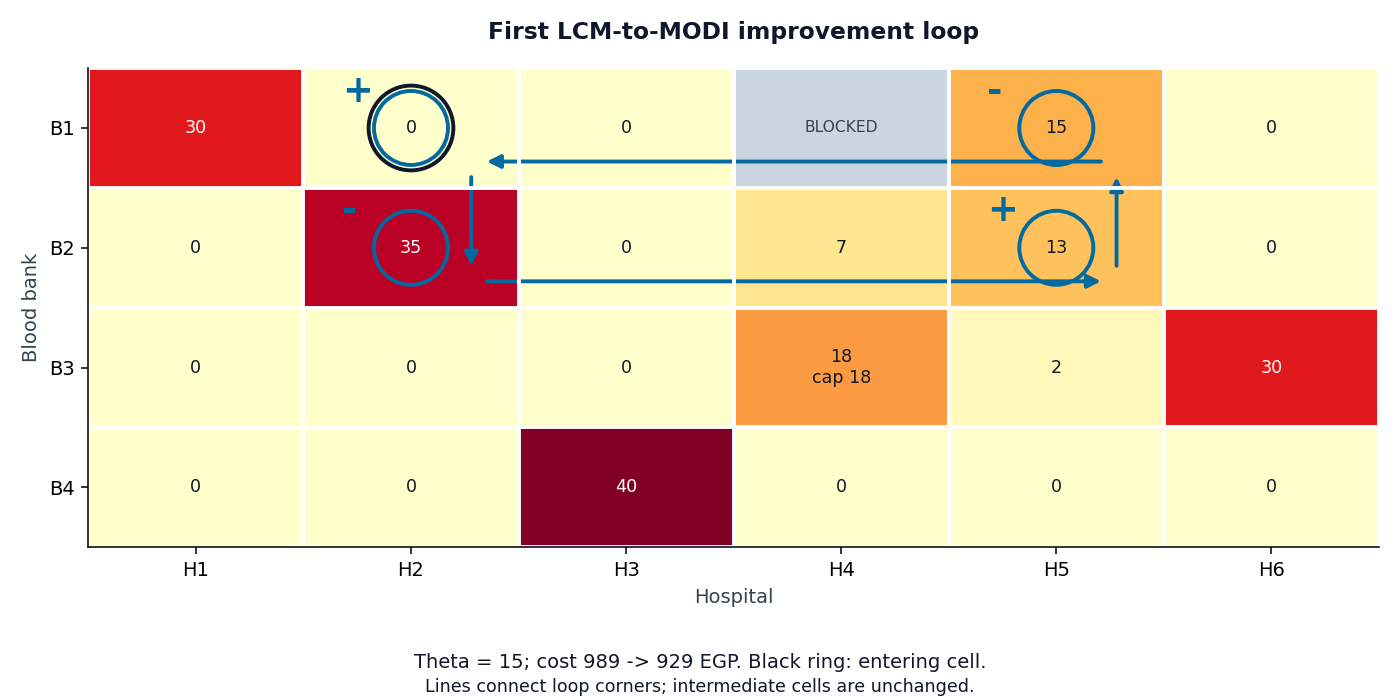

In [23]:
worked_step = base_run['optimized']['LCM']['history'][0]
i,j = worked_step['entering']
display(pd.DataFrame({'Node': BASE.sources+BASE.hospitals,
                      'Potential': np.r_[worked_step['u'],worked_step['v']]}))
display(matrix_frame(BASE,worked_step['delta']))
display(loop_frame(BASE,worked_step))
display(Markdown(
    f'Entering lane: **{BASE.sources[i]} to {BASE.hospitals[j]}**, initially at its lower bound.\n\n'
    f'$$\\Delta_{{{i+1},{j+1}}}={BASE.cost[i,j]:g}'
    f'-({worked_step["u"][i]:g}+({worked_step["v"][j]:g}))={worked_step["delta"][i,j]:g}.$$\n\n'
    f'The minimum allowable loop step is $\\theta={worked_step["theta"]:g}$. '
    'Both subtracting-cell quantities and adding-cell spare capacities are checked.\n\n'
    f'$$Z_{{new}}={worked_step["cost_before"]:g}+'
    f'{worked_step["theta"]:g}\\times({worked_step["direction"]*worked_step["delta"][i,j]:g})'
    f'={worked_step["cost_after"]:g}\\;\\mathrm{{EGP}}.$$'
))
plot_loop(BASE,worked_step,'First LCM-to-MODI improvement loop')


### Final shipment plan and every reduced cost

The table records B/L/U/F status for all 24 cells. A prohibited cell's delta is not an available improvement opportunity. The saturated B3-H4 lane can legitimately have a negative delta and status U.

The bounded dual lower bound is

$$D=u^Ts+v^Td+\sum_{U_{ij}<\infty}U_{ij}\min(0,\Delta_{ij}).$$

Together, primal feasibility, all status-dependent reduced-cost conditions, and $Z-D=0$ certify global optimality for this linear model.


In [24]:
display(matrix_frame(BASE,base_final['x'],margins=True))
display(shipment_table(BASE,base_final['x']))
final_certificate = optimality_certificate(BASE,base_final)
display(pd.DataFrame({'Node': BASE.sources+BASE.hospitals,
                      'Potential': np.r_[base_final['u'],base_final['v']]}))
display(final_certificate['table'])
display(pd.DataFrame([{
    'Primal objective EGP': base_final['cost'], 'Dual bound EGP': final_certificate['dual_value'],
    'Primal-dual gap': final_certificate['gap'], 'Certified optimal': final_certificate['passed']
}]))
assert final_certificate['passed']


,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,Supply
B1 Central,30.0,15.0,0.0,0.0,0.0,0.0,45.0
B2 North,0.0,20.0,0.0,5.0,30.0,0.0,55.0
B3 East,0.0,0.0,2.0,18.0,0.0,30.0,50.0
B4 South,0.0,0.0,38.0,2.0,0.0,0.0,40.0
Demand,30.0,35.0,40.0,25.0,30.0,30.0,190.0


,Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
0,B1 Central,H1 Trauma,30.0,4.0,120.0,Delivered blood
1,B1 Central,H2 Maternity,15.0,6.0,90.0,Delivered blood
2,B2 North,H2 Maternity,20.0,4.0,80.0,Delivered blood
3,B2 North,H4 Surgery,5.0,9.0,45.0,Delivered blood
4,B2 North,H5 Pediatric,30.0,6.0,180.0,Delivered blood
5,B3 East,H3 Oncology,2.0,5.0,10.0,Delivered blood
6,B3 East,H4 Surgery,18.0,3.0,54.0,Delivered blood
7,B3 East,H6 Regional,30.0,6.0,180.0,Delivered blood
8,B4 South,H3 Oncology,38.0,4.0,152.0,Delivered blood
9,B4 South,H4 Surgery,2.0,8.0,16.0,Delivered blood


,Node,Potential
0,B1 Central,0.0
1,B2 North,-2.0
2,B3 East,-2.0
3,B4 South,-3.0
4,H1 Trauma,4.0
5,H2 Maternity,6.0
6,H3 Oncology,7.0
7,H4 Surgery,11.0
8,H5 Pediatric,8.0
9,H6 Regional,8.0


,Source,Hospital,Unit cost,Allocation,Upper bound,Status,Delta,Optimality rule,Passed
0,B1 Central,H1 Trauma,4.0,30.0,inf,B,0.0,Delta = 0,True
1,B1 Central,H2 Maternity,6.0,15.0,inf,B,0.0,Delta = 0,True
2,B1 Central,H3 Oncology,9.0,0.0,inf,L,2.0,Delta >= 0,True
3,B1 Central,H4 Surgery,1.0,0.0,0.0,F,NaN,Excluded / fixed at zero,True
4,B1 Central,H5 Pediatric,12.0,0.0,inf,L,4.0,Delta >= 0,True
5,B1 Central,H6 Regional,10.0,0.0,inf,L,2.0,Delta >= 0,True
6,B2 North,H1 Trauma,7.0,0.0,inf,L,5.0,Delta >= 0,True
7,B2 North,H2 Maternity,4.0,20.0,inf,B,0.0,Delta = 0,True
8,B2 North,H3 Oncology,8.0,0.0,inf,L,3.0,Delta >= 0,True
9,B2 North,H4 Surgery,9.0,5.0,inf,B,0.0,Delta = 0,True


,Primal objective EGP,Dual bound EGP,Primal-dual gap,Certified optimal
0,927.0,927.0,0.0,True


In [25]:
occupied = int(np.count_nonzero(base_final['x']>TOL))
cap_status = cell_status(BASE,base_final['x'],base_final['basis'],(2,3))
display(pd.DataFrame([
    {'Quantity': 'Connected network basis rank', 'Value': base_final['rank']},
    {'Quantity': 'Basic arcs', 'Value': len(base_final['basis'])},
    {'Quantity': 'Occupied cells', 'Value': occupied},
    {'Quantity': 'B3-H4 flow', 'Value': base_final['x'][2,3]},
    {'Quantity': 'B3-H4 capacity', 'Value': BASE.upper[2,3]},
    {'Quantity': 'B3-H4 status', 'Value': cap_status},
    {'Quantity': 'B3-H4 reduced cost', 'Value': base_final['delta'][2,3]}
]))
display(Markdown(f'There are **{occupied} occupied cells** and **{len(base_final["basis"])} basic arcs**. '
                 f'B3-H4 is **{cap_status}**, with reduced cost **{base_final["delta"][2,3]:g}**. '
                 'Its extra positive nonbasic shipment is fixed at its upper bound; it is not an extra basic arc.'))
display(allocation_audit(BASE,base_final['x']))


,Quantity,Value
0,Connected network basis rank,9
1,Basic arcs,9
2,Occupied cells,10
3,B3-H4 flow,18.0
4,B3-H4 capacity,18.0
5,B3-H4 status,U
6,B3-H4 reduced cost,-6.0


There are **10 occupied cells** and **9 basic arcs**. B3-H4 is **U**, with reduced cost **-6**. Its extra positive nonbasic shipment is fixed at its upper bound; it is not an extra basic arc.

,Constraint,Observed,Target / limit,Passed
0,Supply: B1 Central,45.0,45.0,True
1,Supply: B2 North,55.0,55.0,True
2,Supply: B3 East,50.0,50.0,True
3,Supply: B4 South,40.0,40.0,True
4,Demand: H1 Trauma,30.0,30.0,True
5,Demand: H2 Maternity,35.0,35.0,True
6,Demand: H3 Oncology,40.0,40.0,True
7,Demand: H4 Surgery,25.0,25.0,True
8,Demand: H5 Pediatric,30.0,30.0,True
9,Demand: H6 Regional,30.0,30.0,True


### Independent LP verification

The LP uses the identical costs, ten margin equations, nonnegative lower bounds, zero upper bound on B1-H4, and upper bound 18 on B3-H4. This is the many-variable LP verification of the transportation model. A two-variable graphical plot would not represent this 24-variable allocation problem.


In [26]:
display(pd.DataFrame([
    {'Method': method+' + bounded MODI', 'Computed objective': result['cost'],
     'HiGHS objective': base_run['lp']['cost'], 'Absolute difference': abs(result['cost']-base_run['lp']['cost'])}
    for method,result in base_run['optimized'].items()
]))
display(Markdown('Different optimum shipment tables can exist with the same minimum cost. '
                 'Equality with the benchmark objective does not require identical allocations.'))


,Method,Computed objective,HiGHS objective,Absolute difference
0,NWC + bounded MODI,927.0,927.0,0.0
1,LCM + bounded MODI,927.0,927.0,0.0
2,VAM + bounded MODI,927.0,927.0,0.0


Different optimum shipment tables can exist with the same minimum cost. Equality with the benchmark objective does not require identical allocations.

## Results and visual comparisons

Every plotted value below comes from the input arrays or computed results. The initial-cost comparison is separate from the final-cost comparison, and convergence traces use actual MODI pivot costs.


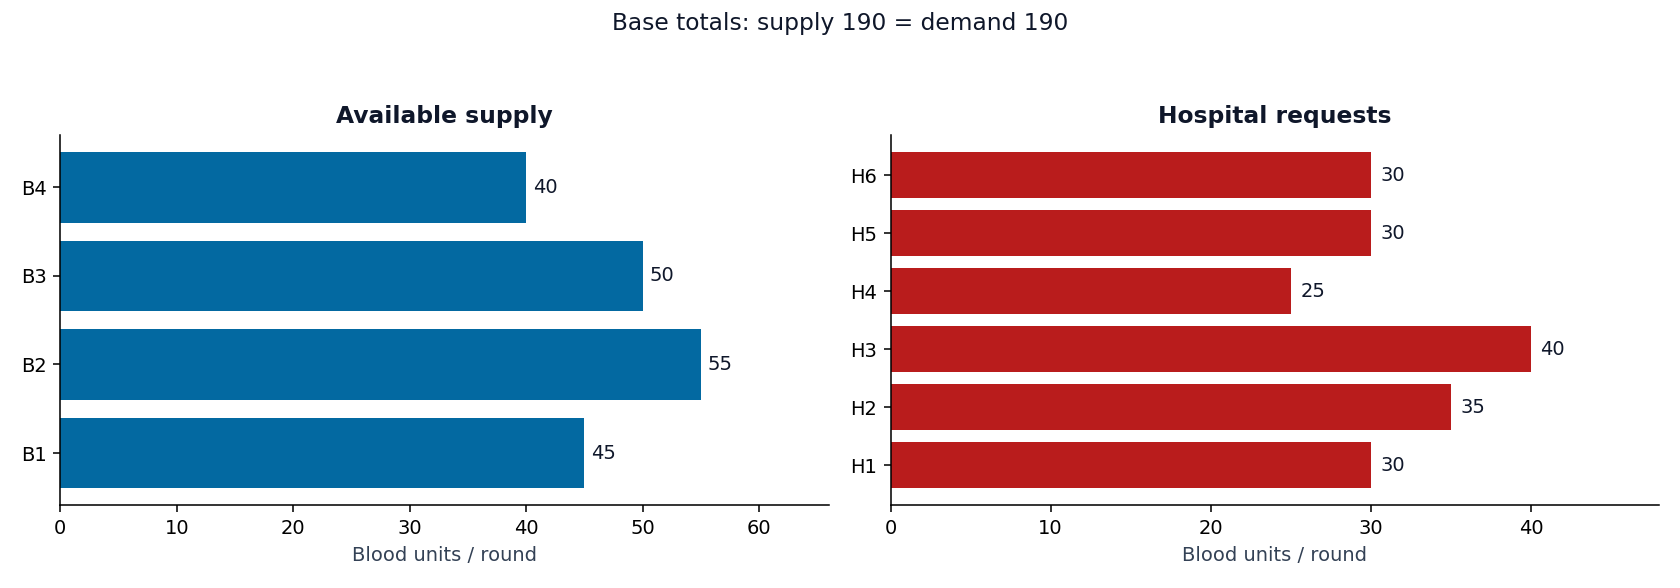

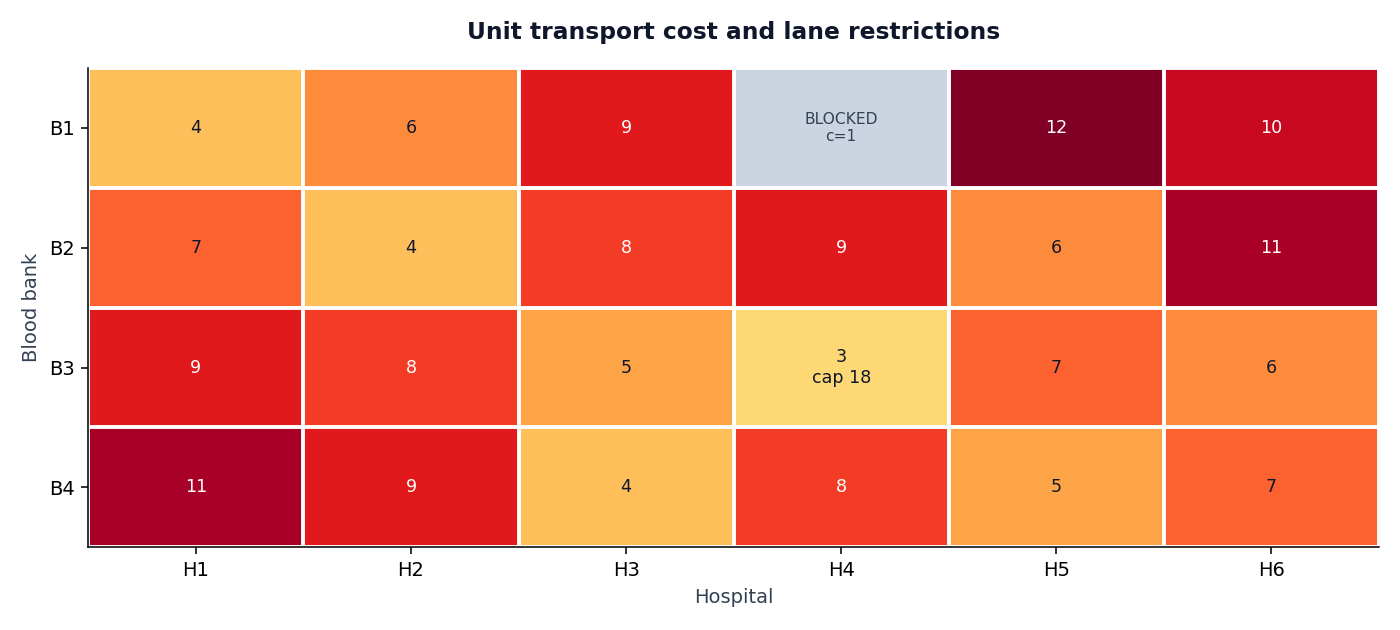

In [27]:
fig,axes = plt.subplots(1,2,figsize=(12,4.2))
axes[0].barh([s.split()[0] for s in BASE.sources],BASE.supply,color='#0369a1')
axes[1].barh([h.split()[0] for h in BASE.hospitals],BASE.demand,color='#b91c1c')
for ax,values,title in zip(axes,[BASE.supply,BASE.demand],['Available supply','Hospital requests']):
    for i,value in enumerate(values): ax.text(value+0.6,i,f'{value:g}',va='center')
    ax.set_xlim(0,max(values)*1.2); ax.set_xlabel('Blood units / round'); ax.set_title(title)
fig.suptitle(f'Base totals: supply {BASE.supply.sum():g} = demand {BASE.demand.sum():g}',y=0.98)
fig.tight_layout(rect=(0,0,1,0.93)); plt.show()
fig,ax = plt.subplots(figsize=(10,4.5))
heatmap(BASE,BASE.cost,'Unit transport cost and lane restrictions',ax,costs=True)
fig.tight_layout(); plt.show()


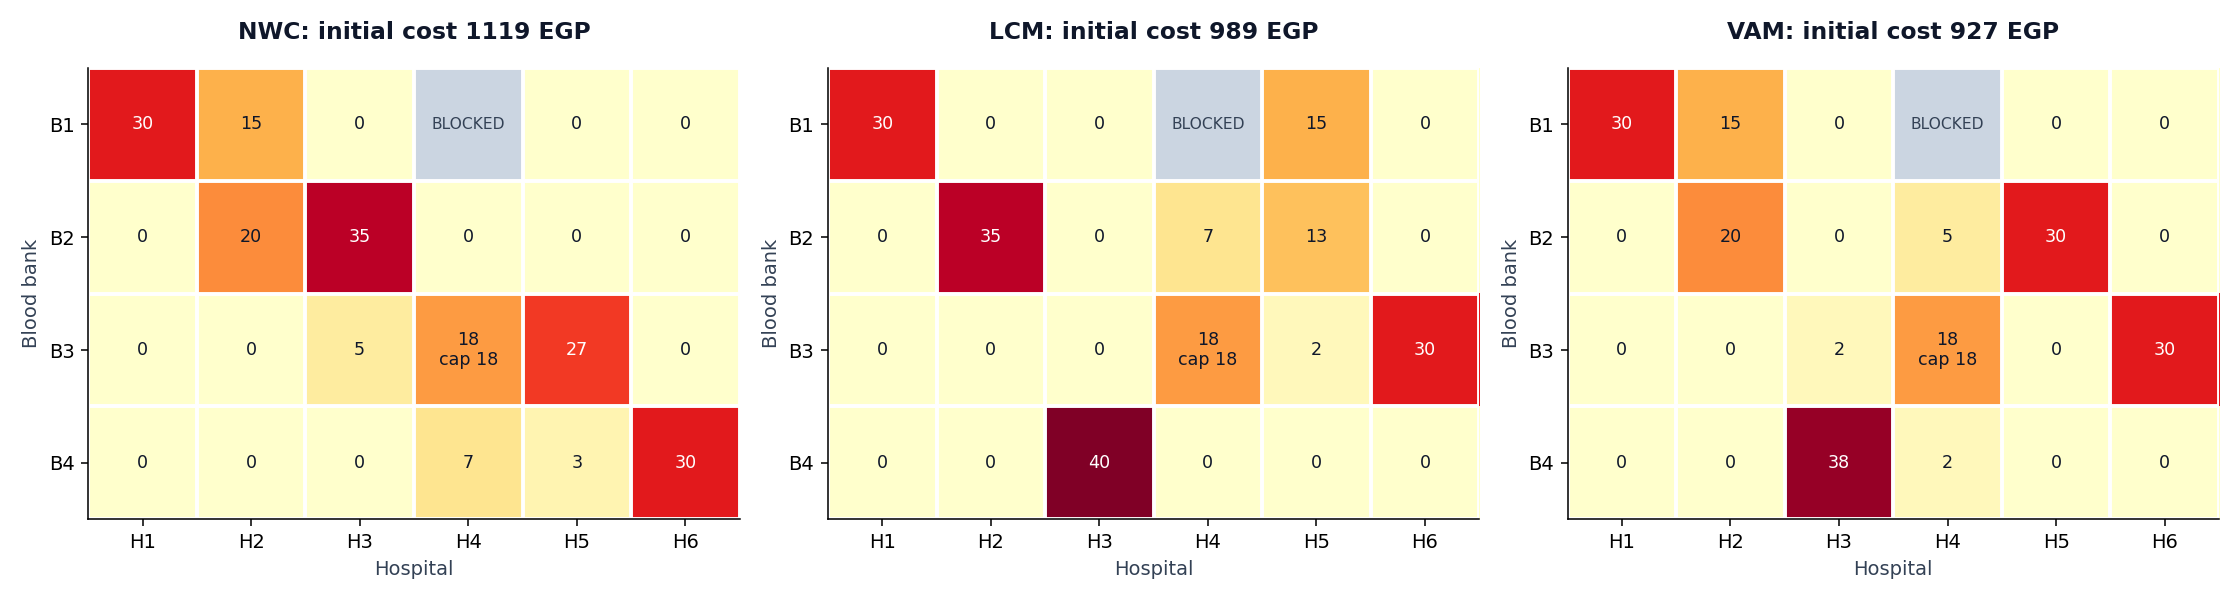

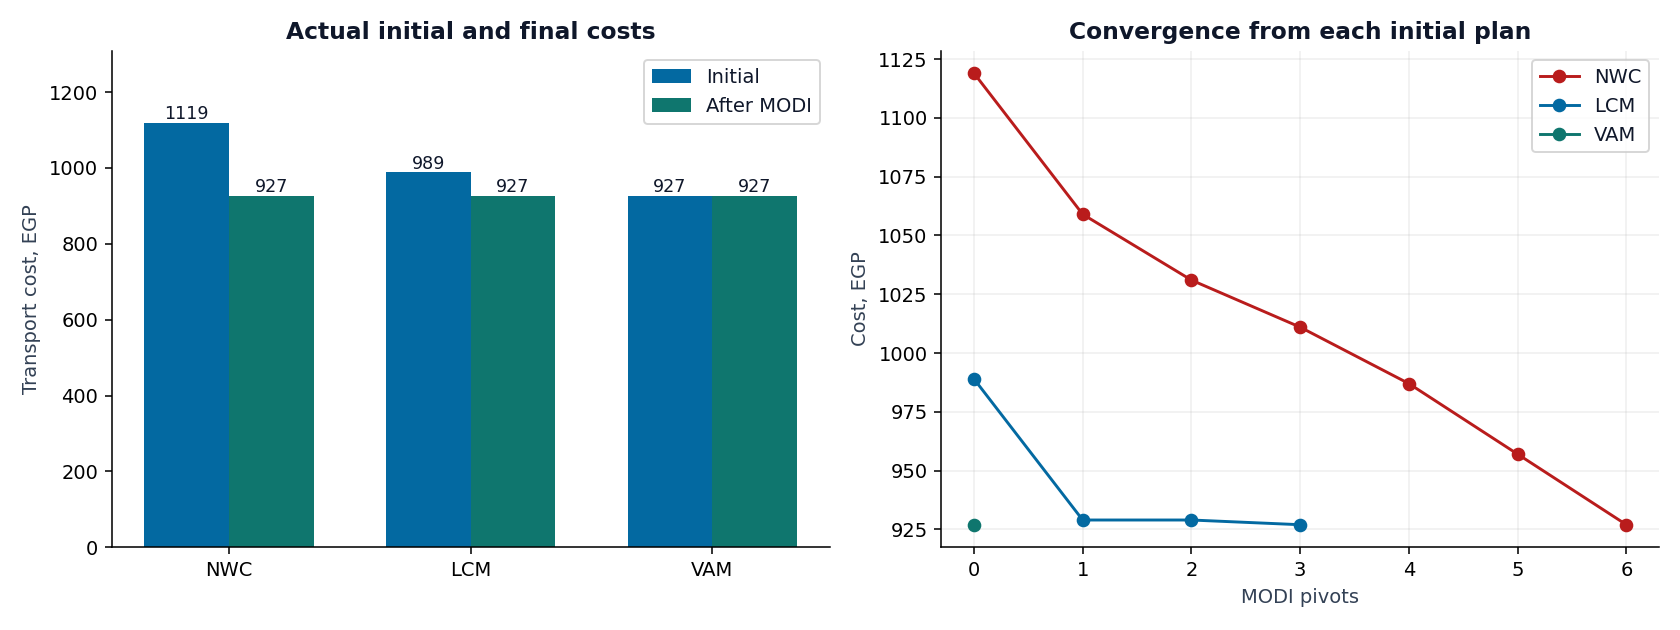

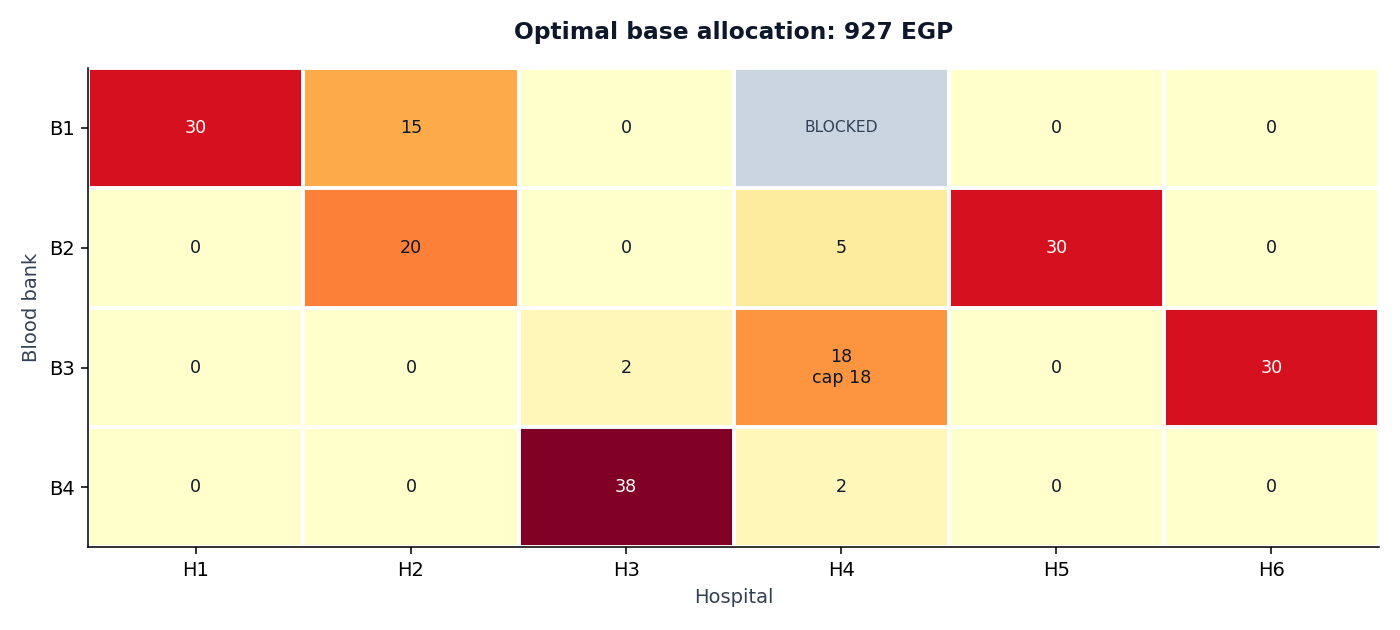

In [28]:
fig,axes = plt.subplots(1,3,figsize=(16,4.3))
common_max = max(result['x'].max() for result in base_run['initial'].values())
for ax,(method,result) in zip(axes,base_run['initial'].items()):
    heatmap(BASE,result['x'],f'{method}: initial cost {result["cost"]:g} EGP',ax,max_value=common_max)
fig.tight_layout(); plt.show()
fig,axes = plt.subplots(1,2,figsize=(12,4.5))
comparison = base_run['comparison']
positions = np.arange(len(comparison))
width = 0.35
axes[0].bar(positions-width/2,comparison['Initial cost EGP'],width,label='Initial',color='#0369a1')
axes[0].bar(positions+width/2,comparison['Final cost EGP'],width,label='After MODI',color='#0f766e')
for k,row in enumerate(comparison.itertuples()):
    axes[0].text(k-width/2,comparison.iloc[k]['Initial cost EGP']+9,f'{comparison.iloc[k]["Initial cost EGP"]:g}',ha='center',fontsize=9)
    axes[0].text(k+width/2,comparison.iloc[k]['Final cost EGP']+9,f'{comparison.iloc[k]["Final cost EGP"]:g}',ha='center',fontsize=9)
axes[0].set_xticks(positions,comparison.index); axes[0].set_ylabel('Transport cost, EGP')
axes[0].set_ylim(0,comparison['Initial cost EGP'].max()*1.17)
axes[0].set_title('Actual initial and final costs'); axes[0].legend()
for method,result in base_run['optimized'].items():
    costs = [result['normalized_start_cost']]+[h['cost_after'] for h in result['history']]
    axes[1].plot(range(len(costs)),costs,marker='o',label=method)
axes[1].set_xlabel('MODI pivots'); axes[1].set_ylabel('Cost, EGP')
axes[1].set_title('Convergence from each initial plan'); axes[1].legend(); axes[1].grid(alpha=.2)
fig.tight_layout(); plt.show()
fig,ax = plt.subplots(figsize=(10,4.5))
heatmap(BASE,base_final['x'],f'Optimal base allocation: {base_final["cost"]:g} EGP',ax)
fig.tight_layout(); plt.show()


## Scenarios and dummy balancing

Each scenario is changed **independently from the base**, not cumulatively. All use the same product and planning round.

| Scenario | Change | Purpose |
|---|---|---|
| Base | B1-H4 prohibited; B3-H4 cap 18 | Main constrained case |
| A | All H4 transport tariffs +20%, rounded to one decimal | Lecture-style cost sensitivity |
| B | H2 demand +10; H5 demand -10 | Balanced demand reallocation |
| C | H1 demand +15; H4 demand +10 | Shortage of 25 units; dummy source |
| D | B3-H4 lane capacity raised from 18 to 30 | Value of extra cold boxes |
| E | B2-H5 delivery service unavailable | Transport resilience |
| F | B4 supply +20 | Surplus of 20 units; dummy destination |

Scenario C uses explicit synthetic shortage penalties `[800, 600, 600, 750, 650, 500]` EGP per unmet unit. They illustrate a stated service-priority policy and are not valuations of patients or clinical recommendations. Dummy flow is recorded as unmet demand, separately from real blood delivery.


In [29]:
def build_scenarios(base):
    scenarios = {'Base': base.copy()}
    cost_spike = base.cost.copy()
    cost_spike[:, 3] = np.round(1.2*cost_spike[:, 3], 1)
    scenarios['A: H4 cost +20%'] = base.copy(name='A: H4 cost +20%', cost=cost_spike)
    shifted = base.demand.copy()
    shifted[1] += 10
    shifted[4] -= 10
    scenarios['B: demand shift'] = base.copy(name='B: demand shift', demand=shifted)
    surge = base.demand.copy()
    surge[0] += 15
    surge[3] += 10
    penalties = np.array([800, 600, 600, 750, 650, 500], float)
    scenarios['C: surge / shortage'] = balance_problem(
        base.copy(name='C: surge / shortage', demand=surge), shortage_penalty=penalties)
    expanded = base.upper.copy()
    expanded[2, 3] = 30
    scenarios['D: extra cold boxes'] = base.copy(name='D: extra cold boxes', upper=expanded)
    interrupted = base.upper.copy()
    interrupted[1, 4] = 0
    scenarios['E: vehicle failure'] = base.copy(name='E: vehicle failure', upper=interrupted)
    extra = base.supply.copy()
    extra[3] += 20
    scenarios['F: surplus inventory'] = balance_problem(base.copy(name='F: surplus inventory', supply=extra))
    return scenarios


In [30]:
scenarios = build_scenarios(BASE)
scenario_runs = {'Base': base_run}
for name,problem in scenarios.items():
    if name != 'Base':
        scenario_runs[name] = solve_case(problem)
scenario_rows = []
comparison_rows = []
for name,run in scenario_runs.items():
    result = run['optimized']['VAM']
    metrics = operational_metrics(run['problem'],result['x'])
    scenario_rows.append({'Scenario': name, **metrics,
                          'B3-H4 flow': result['x'][2,3],
                          'Verified objective': run['lp']['cost']})
    for method,row in run['comparison'].iterrows():
        comparison_rows.append({'Scenario': name, 'Method': method,
                                'Initial cost EGP': row['Initial cost EGP'],
                                'Final cost EGP': row['Final cost EGP'],
                                'MODI pivots': row['MODI pivots'],
                                'Guard events': row['Feasibility guard events']})
scenario_summary = pd.DataFrame(scenario_rows).set_index('Scenario')
all_method_comparisons = pd.DataFrame(comparison_rows)
display(scenario_summary)
display(all_method_comparisons)


,Real delivery units,Unmet demand units,Retained inventory units,Transport cost EGP,Shortage penalty EGP,Objective EGP,B3-H4 flow,Verified objective
Scenario,,,,,,,,
Base,190.0,0.0,0.0,927.0,0.0,927.0,18.0,927.0
A: H4 cost +20%,190.0,0.0,0.0,950.0,0.0,950.0,18.0,950.0
B: demand shift,190.0,0.0,0.0,907.0,0.0,907.0,18.0,907.0
C: surge / shortage,190.0,25.0,0.0,897.0,12500.0,13397.0,18.0,13397.0
D: extra cold boxes,190.0,0.0,0.0,895.0,0.0,895.0,25.0,895.0
E: vehicle failure,190.0,0.0,0.0,996.0,0.0,996.0,18.0,996.0
F: surplus inventory,190.0,0.0,20.0,877.0,0.0,877.0,18.0,877.0


,Scenario,Method,Initial cost EGP,Final cost EGP,MODI pivots,Guard events
0,Base,NWC,1119.0,927.0,6,0
1,Base,LCM,989.0,927.0,3,2
2,Base,VAM,927.0,927.0,0,2
3,A: H4 cost +20%,NWC,1141.0,950.0,6,0
4,A: H4 cost +20%,LCM,1012.4,950.0,3,2
5,A: H4 cost +20%,VAM,950.0,950.0,0,2
6,B: demand shift,NWC,1059.0,907.0,6,0
7,B: demand shift,LCM,969.0,907.0,3,2
8,B: demand shift,VAM,907.0,907.0,0,2
9,C: surge / shortage,NWC,13479.0,13397.0,6,0


### Final shipment tables: base, A, and B

These are the main shipment tables requested by the lecture-style exercise. The remaining cases follow in expandable tables. Dummy entries are explicitly labeled so they cannot be mistaken for delivered blood.


In [31]:
for name,run in scenario_runs.items():
    table = shipment_table(run['problem'],run['optimized']['VAM']['x'])
    if name in ('Base','A: H4 cost +20%','B: demand shift'):
        display(Markdown(f'**{name}: final shipments**'))
        display(table)
    else:
        display(HTML(f'<details><summary><b>{name}: final shipments</b></summary>'
                     +table.to_html(index=False)+'</details>'))


**Base: final shipments**

,Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
0,B1 Central,H1 Trauma,30.0,4.0,120.0,Delivered blood
1,B1 Central,H2 Maternity,15.0,6.0,90.0,Delivered blood
2,B2 North,H2 Maternity,20.0,4.0,80.0,Delivered blood
3,B2 North,H4 Surgery,5.0,9.0,45.0,Delivered blood
4,B2 North,H5 Pediatric,30.0,6.0,180.0,Delivered blood
5,B3 East,H3 Oncology,2.0,5.0,10.0,Delivered blood
6,B3 East,H4 Surgery,18.0,3.0,54.0,Delivered blood
7,B3 East,H6 Regional,30.0,6.0,180.0,Delivered blood
8,B4 South,H3 Oncology,38.0,4.0,152.0,Delivered blood
9,B4 South,H4 Surgery,2.0,8.0,16.0,Delivered blood


**A: H4 cost +20%: final shipments**

,Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
0,B1 Central,H1 Trauma,30.0,4.0,120.0,Delivered blood
1,B1 Central,H2 Maternity,15.0,6.0,90.0,Delivered blood
2,B2 North,H2 Maternity,20.0,4.0,80.0,Delivered blood
3,B2 North,H4 Surgery,5.0,10.8,54.0,Delivered blood
4,B2 North,H5 Pediatric,30.0,6.0,180.0,Delivered blood
5,B3 East,H3 Oncology,2.0,5.0,10.0,Delivered blood
6,B3 East,H4 Surgery,18.0,3.6,64.8,Delivered blood
7,B3 East,H6 Regional,30.0,6.0,180.0,Delivered blood
8,B4 South,H3 Oncology,38.0,4.0,152.0,Delivered blood
9,B4 South,H4 Surgery,2.0,9.6,19.2,Delivered blood


**B: demand shift: final shipments**

,Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
0,B1 Central,H1 Trauma,30.0,4.0,120.0,Delivered blood
1,B1 Central,H2 Maternity,15.0,6.0,90.0,Delivered blood
2,B2 North,H2 Maternity,30.0,4.0,120.0,Delivered blood
3,B2 North,H4 Surgery,5.0,9.0,45.0,Delivered blood
4,B2 North,H5 Pediatric,20.0,6.0,120.0,Delivered blood
5,B3 East,H3 Oncology,2.0,5.0,10.0,Delivered blood
6,B3 East,H4 Surgery,18.0,3.0,54.0,Delivered blood
7,B3 East,H6 Regional,30.0,6.0,180.0,Delivered blood
8,B4 South,H3 Oncology,38.0,4.0,152.0,Delivered blood
9,B4 South,H4 Surgery,2.0,8.0,16.0,Delivered blood


Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
B1 Central,H1 Trauma,45.0,4.0,180.0,Delivered blood
B2 North,H2 Maternity,35.0,4.0,140.0,Delivered blood
B2 North,H5 Pediatric,20.0,6.0,120.0,Delivered blood
B3 East,H3 Oncology,27.0,5.0,135.0,Delivered blood
B3 East,H4 Surgery,18.0,3.0,54.0,Delivered blood
B3 East,H6 Regional,5.0,6.0,30.0,Delivered blood
B4 South,H3 Oncology,13.0,4.0,52.0,Delivered blood
B4 South,H4 Surgery,17.0,8.0,136.0,Delivered blood
B4 South,H5 Pediatric,10.0,5.0,50.0,Delivered blood
DUMMY: unmet demand,H6 Regional,25.0,500.0,12500.0,Unmet demand


Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
B1 Central,H1 Trauma,30.0,4.0,120.0,Delivered blood
B1 Central,H2 Maternity,10.0,6.0,60.0,Delivered blood
B1 Central,H6 Regional,5.0,10.0,50.0,Delivered blood
B2 North,H2 Maternity,25.0,4.0,100.0,Delivered blood
B2 North,H5 Pediatric,30.0,6.0,180.0,Delivered blood
B3 East,H4 Surgery,25.0,3.0,75.0,Delivered blood
B3 East,H6 Regional,25.0,6.0,150.0,Delivered blood
B4 South,H3 Oncology,40.0,4.0,160.0,Delivered blood


Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
B1 Central,H1 Trauma,30.0,4.0,120.0,Delivered blood
B1 Central,H3 Oncology,15.0,9.0,135.0,Delivered blood
B2 North,H2 Maternity,35.0,4.0,140.0,Delivered blood
B2 North,H3 Oncology,13.0,8.0,104.0,Delivered blood
B2 North,H4 Surgery,7.0,9.0,63.0,Delivered blood
B3 East,H3 Oncology,2.0,5.0,10.0,Delivered blood
B3 East,H4 Surgery,18.0,3.0,54.0,Delivered blood
B3 East,H6 Regional,30.0,6.0,180.0,Delivered blood
B4 South,H3 Oncology,10.0,4.0,40.0,Delivered blood
B4 South,H5 Pediatric,30.0,5.0,150.0,Delivered blood


Source,Hospital,Units,Unit cost,Cost contribution,Interpretation
B1 Central,H1 Trauma,30.0,4.0,120.0,Delivered blood
B1 Central,DUMMY: retained inventory,15.0,0.0,0.0,Retained inventory
B2 North,H2 Maternity,35.0,4.0,140.0,Delivered blood
B2 North,H5 Pediatric,17.0,6.0,102.0,Delivered blood
B2 North,DUMMY: retained inventory,3.0,0.0,0.0,Retained inventory
B3 East,H4 Surgery,18.0,3.0,54.0,Delivered blood
B3 East,H6 Regional,30.0,6.0,180.0,Delivered blood
B3 East,DUMMY: retained inventory,2.0,0.0,0.0,Retained inventory
B4 South,H3 Oncology,40.0,4.0,160.0,Delivered blood
B4 South,H4 Surgery,7.0,8.0,56.0,Delivered blood


### Dummy mathematics and interpretation

**Shortage:** real demand is $215$ and real supply is $190$. Add a dummy source with supply $25$:

$$\sum_{i\in I_{real}}x_{ij}+y_j=d_j,\qquad \sum_j y_j=25.$$

Here $y_j$ is unmet demand. The objective is physical transport cost plus the declared shortage penalties:

$$\min\left(\sum_{i\in I_{real},j}c_{ij}x_{ij}+\sum_j p_j y_j\right).$$

**Surplus:** real supply is $210$ and real demand is $190$. Add a dummy destination with demand $20$. Flow to it means inventory retained at its source. A zero dummy tariff assumes no additional holding charge for this round; it does not mean those units were discarded.

The dummy quantity is fixed by the totals. With prohibitions and capacities, balancing alone still requires a feasibility check. A real emergency supplier would need its own actual capacity and cost data; a dummy source is not a physical supplier.

**Two different penalties:** VAM's penalty is a local difference between two eligible transport costs. Scenario C's shortage penalty is an objective coefficient representing a declared service policy.


In [32]:
for name in ('C: surge / shortage','F: surplus inventory'):
    run = scenario_runs[name]; problem = run['problem']; x = run['optimized']['VAM']['x']
    display(Markdown(f'**{name}: balanced allocation table**'))
    display(matrix_frame(problem,x,margins=True))
    display(pd.DataFrame([operational_metrics(problem,x)]))
short_run = scenario_runs['C: surge / shortage']
short_p,short_x = short_run['problem'],short_run['optimized']['VAM']['x']
display(pd.DataFrame({
    'Hospital': short_p.hospitals,
    'Requested units': short_p.demand,
    'Real delivered units': short_x[:short_p.real_rows,:].sum(axis=0),
    'Unmet units (dummy)': short_x[short_p.real_rows:,:].sum(axis=0),
    'Shortage penalty per unit': short_p.cost[-1]
}))
assert short_x[:short_p.real_rows,:].sum()==190
assert short_x[short_p.real_rows:,:].sum()==25


**C: surge / shortage: balanced allocation table**

,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,Supply
B1 Central,45.0,0.0,0.0,0.0,0.0,0.0,45.0
B2 North,0.0,35.0,0.0,0.0,20.0,0.0,55.0
B3 East,0.0,0.0,27.0,18.0,0.0,5.0,50.0
B4 South,0.0,0.0,13.0,17.0,10.0,0.0,40.0
DUMMY: unmet demand,0.0,0.0,0.0,0.0,0.0,25.0,25.0
Demand,45.0,35.0,40.0,35.0,30.0,30.0,215.0


,Real delivery units,Unmet demand units,Retained inventory units,Transport cost EGP,Shortage penalty EGP,Objective EGP
0,190.0,25.0,0.0,897.0,12500.0,13397.0


**F: surplus inventory: balanced allocation table**

,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,DUMMY: retained inventory,Supply
B1 Central,30.0,0.0,0.0,0.0,0.0,0.0,15.0,45.0
B2 North,0.0,35.0,0.0,0.0,17.0,0.0,3.0,55.0
B3 East,0.0,0.0,0.0,18.0,0.0,30.0,2.0,50.0
B4 South,0.0,0.0,40.0,7.0,13.0,0.0,0.0,60.0
Demand,30.0,35.0,40.0,25.0,30.0,30.0,20.0,210.0


,Real delivery units,Unmet demand units,Retained inventory units,Transport cost EGP,Shortage penalty EGP,Objective EGP
0,190.0,0.0,20.0,877.0,0.0,877.0


,Hospital,Requested units,Real delivered units,Unmet units (dummy),Shortage penalty per unit
0,H1 Trauma,45.0,45.0,0.0,800.0
1,H2 Maternity,35.0,35.0,0.0,600.0
2,H3 Oncology,40.0,40.0,0.0,600.0
3,H4 Surgery,35.0,35.0,0.0,750.0
4,H5 Pediatric,30.0,30.0,0.0,650.0
5,H6 Regional,30.0,5.0,25.0,500.0


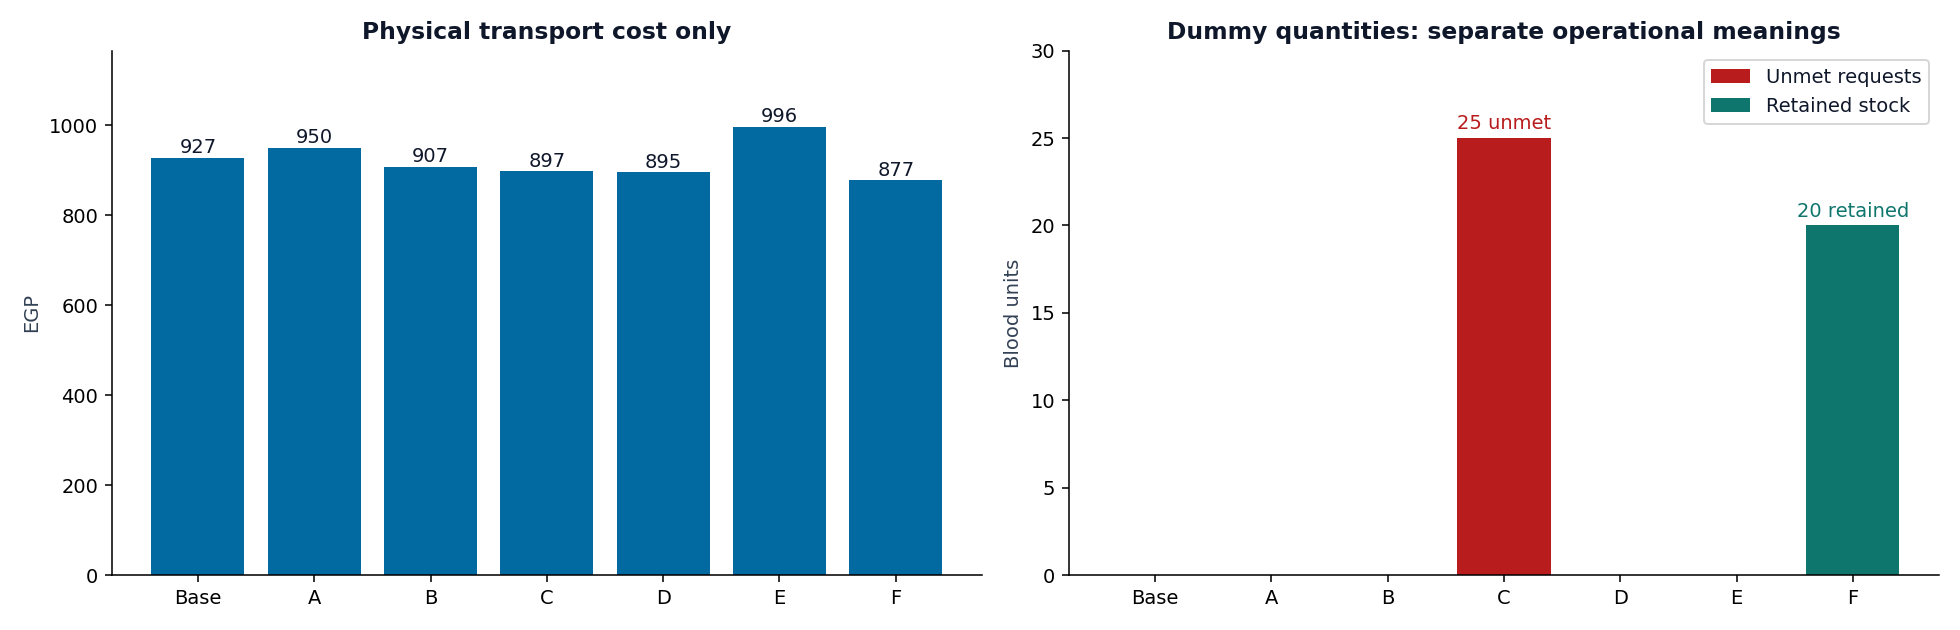

Scenario C's objective includes a shortage penalty. Its physical transport cost alone cannot be interpreted as the cost of fulfilling all requests.

In [33]:
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
labels = ['Base','A','B','C','D','E','F']
axes[0].bar(labels,scenario_summary['Transport cost EGP'],color='#0369a1')
for i,value in enumerate(scenario_summary['Transport cost EGP']):
    axes[0].text(i,value+10,f'{value:g}',ha='center')
axes[0].set_ylim(0,scenario_summary['Transport cost EGP'].max()*1.17)
axes[0].set_title('Physical transport cost only'); axes[0].set_ylabel('EGP')
axes[1].bar(labels,scenario_summary['Unmet demand units'],color='#b91c1c',label='Unmet requests')
axes[1].bar(labels,scenario_summary['Retained inventory units'],bottom=scenario_summary['Unmet demand units'],
            color='#0f766e',label='Retained stock')
axes[1].set_title('Dummy quantities: separate operational meanings')
axes[1].set_ylabel('Blood units'); axes[1].legend()
axes[1].set_ylim(0,30)
axes[1].text(3,25.5,'25 unmet',ha='center',color='#b91c1c')
axes[1].text(6,20.5,'20 retained',ha='center',color='#0f766e')
fig.tight_layout(); plt.show()
display(Markdown("Scenario C's objective includes a shortage penalty. "
                 'Its physical transport cost alone cannot be interpreted as the cost of fulfilling all requests.'))


### Warm start after the cost spike

Scenario A keeps supply, demand, and bounds unchanged, so the base shipment plan and basis are feasible warm starts. The **new costs must be used to recompute potentials and deltas**; the old potentials are not blindly reused as if their basic-cell equations were unchanged.


In [34]:
case_a = scenarios['A: H4 cost +20%']
warm_a = bounded_modi(case_a,base_final['x'],initial_basis=base_final['basis'])
assert abs(warm_a['cost']-scenario_runs['A: H4 cost +20%']['lp']['cost'])<TOL
display(pd.DataFrame([{
    'Cost of base shipments at new tariffs': total_cost(case_a,base_final['x']),
    'Warm-start optimal cost': warm_a['cost'], 'Warm-start MODI pivots': len(warm_a['history']),
    'Original potentials still satisfy new basic equations':
        all(abs(case_a.cost[e]-base_final['u'][e[0]]-base_final['v'][e[1]])<TOL for e in base_final['basis'])
}]))
display(optimality_certificate(case_a,warm_a)['table'])


,Cost of base shipments at new tariffs,Warm-start optimal cost,Warm-start MODI pivots,Original potentials still satisfy new basic equations
0,950.0,950.0,0,False


,Source,Hospital,Unit cost,Allocation,Upper bound,Status,Delta,Optimality rule,Passed
0,B1 Central,H1 Trauma,4.0,30.0,inf,B,0.0,Delta = 0,True
1,B1 Central,H2 Maternity,6.0,15.0,inf,B,0.0,Delta = 0,True
2,B1 Central,H3 Oncology,9.0,0.0,inf,L,1.8,Delta >= 0,True
3,B1 Central,H4 Surgery,1.2,0.0,0.0,F,NaN,Excluded / fixed at zero,True
4,B1 Central,H5 Pediatric,12.0,0.0,inf,L,4.0,Delta >= 0,True
5,B1 Central,H6 Regional,10.0,0.0,inf,L,1.8,Delta >= 0,True
6,B2 North,H1 Trauma,7.0,0.0,inf,L,5.0,Delta >= 0,True
7,B2 North,H2 Maternity,4.0,20.0,inf,B,0.0,Delta = 0,True
8,B2 North,H3 Oncology,8.0,0.0,inf,L,2.8,Delta >= 0,True
9,B2 North,H4 Surgery,10.8,5.0,inf,B,0.0,Delta = 0,True


### Repair the plan after the balanced demand shift

The base table does not automatically satisfy Scenario B's new destination totals. A residual alternating path transfers flow from over-supplied hospitals to under-supplied hospitals while preserving every source total and lane bound. MODI then optimizes the repaired feasible plan. If a repaired plan contains an interior cycle, the logged basis-preparation step handles it.


In [35]:
case_b = scenarios['B: demand shift']
repaired_b,repair_history = repair_changed_demands(case_b,base_final['x'])
display(pd.DataFrame([
    {'Reduce hospital': case_b.hospitals[h['from_hospital']],
     'Increase hospital': case_b.hospitals[h['to_hospital']], 'Units reassigned': h['quantity'],
     'Signed path': ' ; '.join(f'{case_b.sources[i]} to {case_b.hospitals[j]}: {sign:+d}' for (i,j),sign in h['path'])}
    for h in repair_history
]))
warm_b = bounded_modi(case_b,repaired_b)
assert abs(warm_b['cost']-scenario_runs['B: demand shift']['lp']['cost'])<TOL
display(matrix_frame(case_b,warm_b['x'],margins=True))
display(pd.DataFrame([{'Repaired cost': total_cost(case_b,repaired_b),
                       'Final cost': warm_b['cost'], 'MODI pivots after repair': len(warm_b['history'])}]))


,Reduce hospital,Increase hospital,Units reassigned,Signed path
0,H5 Pediatric,H2 Maternity,10.0,B2 North to H5 Pediatric: -1 ; B2 North to H2 ...


,H1 Trauma,H2 Maternity,H3 Oncology,H4 Surgery,H5 Pediatric,H6 Regional,Supply
B1 Central,30.0,15.0,0.0,0.0,0.0,0.0,45.0
B2 North,0.0,30.0,0.0,5.0,20.0,0.0,55.0
B3 East,0.0,0.0,2.0,18.0,0.0,30.0,50.0
B4 South,0.0,0.0,38.0,2.0,0.0,0.0,40.0
Demand,30.0,45.0,40.0,25.0,20.0,30.0,190.0


,Repaired cost,Final cost,MODI pivots after repair
0,907.0,907.0,0


### VAM and LCM can change places

The comparison uses the same instance and declared tie rules for every method. Equality of some initial costs is allowed. VAM is a heuristic, not a theorem that it always beats LCM. The surplus case is a useful observed counterexample in this case study; its zero-cost dummy destination changes the allocation choices.


In [36]:
surplus_comparison = scenario_runs['F: surplus inventory']['comparison']
display(surplus_comparison[['Initial cost EGP','Final cost EGP','MODI pivots','Feasibility guard events']])
assert surplus_comparison.loc['LCM','Initial cost EGP'] < surplus_comparison.loc['VAM','Initial cost EGP']


,Initial cost EGP,Final cost EGP,MODI pivots,Feasibility guard events
Method,,,,
NWC,1119.0,877.0,6,0
LCM,896.0,877.0,2,2
VAM,943.0,877.0,3,0


## Sensitivity and constraint effects

### Value of additional cold-chain capacity

The B3-H4 capacity is varied from 0 to 31 units with all other base inputs fixed. Each point is solved with VAM plus bounded MODI and independently checked by LP. The curve shows when an extra unit-slot has value and when further expansion has no effect.

At a saturated nonbasic arc, $-\Delta_{ij}$ is a capacity value for the current optimal basis. It is a local sensitivity quantity, not a guarantee that the same saving continues after arbitrarily large expansions. A capacity can be binding yet have zero marginal value at a breakpoint or under degeneracy.


,Capacity,Optimal cost EGP,Flow on B3-H4,Saving from previous slot EGP
0,0,1035.0,0.0,NaN
6,6,999.0,6.0,6.0
12,12,963.0,12.0,6.0
18,18,927.0,18.0,6.0
19,19,921.0,19.0,6.0
20,20,915.0,20.0,6.0
21,21,911.0,21.0,4.0
22,22,907.0,22.0,4.0
23,23,903.0,23.0,4.0
24,24,899.0,24.0,4.0


,Base capacity,Current-basis capacity value EGP / slot,First capacity attaining frontier minimum,Minimum cost on this frontier,Base-to-frontier saving EGP
0,18.0,6.0,25,895.0,32.0


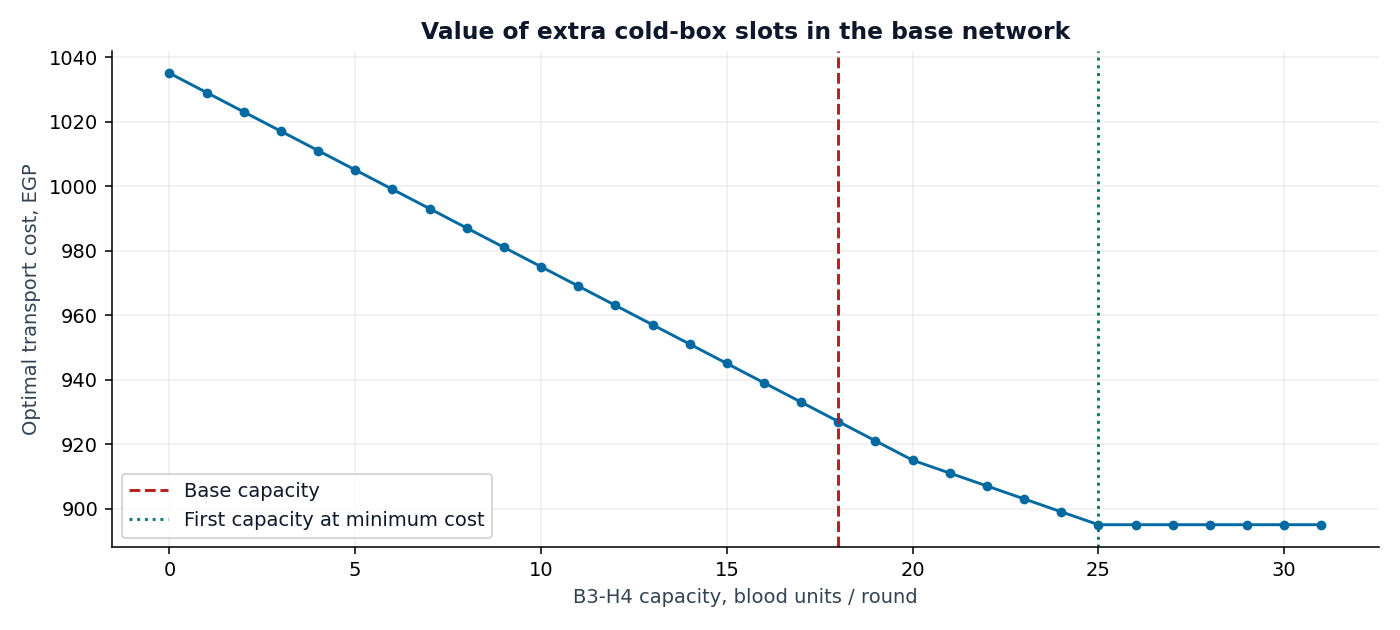

In [37]:
frontier_rows = []
for capacity in range(32):
    upper = BASE.upper.copy(); upper[2,3] = capacity
    problem = BASE.copy(name=f'Capacity {capacity}',upper=upper)
    start = initial_solution(problem,'VAM')
    answer = bounded_modi(problem,start['x'])
    reference = reference_lp(problem)
    assert abs(answer['cost']-reference['cost'])<TOL
    frontier_rows.append({'Capacity': capacity, 'Optimal cost EGP': answer['cost'],
                          'Flow on B3-H4': answer['x'][2,3]})
capacity_frontier = pd.DataFrame(frontier_rows)
capacity_frontier['Saving from previous slot EGP'] = -capacity_frontier['Optimal cost EGP'].diff()
best_frontier_cost = capacity_frontier['Optimal cost EGP'].min()
first_sufficient_capacity = int(capacity_frontier.loc[
    abs(capacity_frontier['Optimal cost EGP']-best_frontier_cost)<TOL,'Capacity'].min())
display(capacity_frontier.loc[capacity_frontier['Capacity'].isin([0,6,12,18,19,20,21,22,23,24,25,30,31])])
display(pd.DataFrame([{
    'Base capacity': BASE.upper[2,3], 'Current-basis capacity value EGP / slot': -base_final['delta'][2,3],
    'First capacity attaining frontier minimum': first_sufficient_capacity,
    'Minimum cost on this frontier': best_frontier_cost,
    'Base-to-frontier saving EGP': base_final['cost']-best_frontier_cost
}]))
fig,ax = plt.subplots(figsize=(10,4.5))
ax.plot(capacity_frontier['Capacity'],capacity_frontier['Optimal cost EGP'],marker='o',markersize=4,color='#0369a1')
ax.axvline(BASE.upper[2,3],color='#b91c1c',linestyle='--',label='Base capacity')
ax.axvline(first_sufficient_capacity,color='#0f766e',linestyle=':',label='First capacity at minimum cost')
ax.set_xlabel('B3-H4 capacity, blood units / round'); ax.set_ylabel('Optimal transport cost, EGP')
ax.set_title('Value of extra cold-box slots in the base network'); ax.grid(alpha=.2); ax.legend()
fig.tight_layout(); plt.show()


### Constraint ablation: quantify the effect of each restriction

The following are explicitly **counterfactual calculations**, not operational recommendations to use an unqualified lane or exceed the actual container capacity. They show what the mathematical cost would be if the respective restriction did not exist, with the same supplies and demands.


In [38]:
ablation_rows = []
for label,remove_forbidden,remove_cap in [
    ('Full policy',False,False), ('Without prohibition',True,False),
    ('Without lane cap',False,True), ('Without either restriction',True,True)
]:
    upper = BASE.upper.copy()
    if remove_forbidden: upper[0,3] = np.inf
    if remove_cap: upper[2,3] = np.inf
    problem = BASE.copy(name=label,upper=upper)
    start = initial_solution(problem,'VAM')
    answer = bounded_modi(problem,start['x'])
    assert abs(answer['cost']-reference_lp(problem)['cost'])<TOL
    ablation_rows.append({
        'Counterfactual': label, 'Optimal cost EGP': answer['cost'],
        'B1-H4 flow': answer['x'][0,3], 'B3-H4 flow': answer['x'][2,3],
        'Prohibited flow under full policy': answer['x'][0,3],
        'Capacity excess under full policy': max(0,answer['x'][2,3]-BASE.upper[2,3]),
        'Complies with full policy': bool(answer['x'][0,3]<TOL and answer['x'][2,3]<=BASE.upper[2,3]+TOL)
    })
ablation_table = pd.DataFrame(ablation_rows)
display(ablation_table)


,Counterfactual,Optimal cost EGP,B1-H4 flow,B3-H4 flow,Prohibited flow under full policy,Capacity excess under full policy,Complies with full policy
0,Full policy,927.0,0.0,18.0,0.0,0.0,True
1,Without prohibition,825.0,15.0,10.0,15.0,0.0,False
2,Without lane cap,895.0,0.0,25.0,0.0,7.0,False
3,Without either restriction,825.0,15.0,10.0,15.0,0.0,False


### A balanced but infeasible scenario

To demonstrate a genuine feasibility failure, close every incoming H4 lane while leaving its request unchanged. Supply and demand still have equal totals. The model must report that the network cannot fulfill the requests; adding a zero-size dummy does not repair a blocked hospital.


In [39]:
blocked_upper = BASE.upper.copy(); blocked_upper[:,3] = 0
blocked_case = BASE.copy(name='G: H4 disconnected',upper=blocked_upper)
blocked_check = transport_feasibility(blocked_case.supply,blocked_case.demand,blocked_case.upper)
display(pd.DataFrame([{
    'Supply total': blocked_case.supply.sum(), 'Demand total': blocked_case.demand.sum(),
    'Maximum deliverable flow': blocked_check['max_flow'],
    'Coverage deficit': blocked_check['required']-blocked_check['max_flow'],
    'Feasible': blocked_check['feasible'], 'Diagnostic': blocked_check['reason']
}]))
assert not blocked_check['feasible']
display(Markdown('A real repair would require an actual eligible service, changed capacity, or a declared shortage model. '
                 'This infeasible case is kept out of the feasible-cost comparison.'))


,Supply total,Demand total,Maximum deliverable flow,Coverage deficit,Feasible,Diagnostic
0,190.0,190.0,165.0,25.0,False,A route/capacity cut prevents full coverage.


A real repair would require an actual eligible service, changed capacity, or a declared shortage model. This infeasible case is kept out of the feasible-cost comparison.

### Lanes used consistently across scenarios

The table counts real blood-delivery lanes, excluding dummy flows. Persistent use is descriptive evidence from these simulated scenarios, not proof that a route is indispensable under every possible future demand.


In [40]:
usage = np.zeros(BASE.shape,dtype=int)
for run in scenario_runs.values():
    usage += run['optimized']['VAM']['x'][:BASE.real_rows,:BASE.real_cols]>TOL
usage_rows = [{'Lane': f'{BASE.sources[i]} to {BASE.hospitals[j]}',
               'Scenarios used': usage[i,j], 'Scenarios tested': len(scenario_runs)}
              for i,j in np.argwhere(usage>0)]
lane_consistency = pd.DataFrame(usage_rows).sort_values(['Scenarios used','Lane'],ascending=[False,True])
display(lane_consistency)


,Lane,Scenarios used,Scenarios tested
0,B1 Central to H1 Trauma,7,7
4,B2 North to H2 Maternity,7,7
9,B3 East to H4 Surgery,7,7
10,B3 East to H6 Regional,7,7
11,B4 South to H3 Oncology,7,7
7,B2 North to H5 Pediatric,6,7
8,B3 East to H3 Oncology,5,7
12,B4 South to H4 Surgery,5,7
1,B1 Central to H2 Maternity,4,7
6,B2 North to H4 Surgery,4,7


## Managerial memo and presentation points

### Managerial memo: at most 200 words

All numerical statements below are generated from the solved cases. The memo reports physical shortfalls separately from the objective's shortage penalty.


In [41]:
base_cost = base_final['cost']
a_cost = scenario_runs['A: H4 cost +20%']['optimized']['VAM']['cost']
b_cost = scenario_runs['B: demand shift']['optimized']['VAM']['cost']
surge_metrics = operational_metrics(short_p,short_x)
nw_saving = base_run['comparison'].loc['NWC','Saving EGP']
memo = (
    f'HemoLink meets all {BASE.demand.sum():g} base-round requests at a minimum transport cost of '
    f'{base_cost:g} EGP, saving {nw_saving:g} EGP against the Northwest Corner starting plan. '
    'The unqualified B1-H4 service remains unused despite its low quoted tariff. '
    f'The B3-H4 capacity of {BASE.upper[2,3]:g} units binds. '
    f'Increasing that capacity to {first_sufficient_capacity} units reaches the tested minimum of '
    f'{best_frontier_cost:g} EGP; additional slots offer no further base-case saving. '
    f'The H4 tariff increase raises optimal cost to {a_cost:g} EGP, while the balanced demand shift costs {b_cost:g} EGP. '
    f'The surge case leaves {surge_metrics["Unmet demand units"]:g} units unmet; dummy flow records this shortfall rather than a delivery. '
    'All results satisfy the stated lane limits and match an independent LP benchmark. '
    'Management should evaluate the cost of extra qualified cold boxes, maintain backup transport services, and monitor hospital coverage during surges. '
    'These recommendations are conditional on the synthetic case inputs.'
)
assert len(memo.split())<=200
display(Markdown(memo))
display(pd.DataFrame([{'Memo word count': len(memo.split()), 'Word limit': 200}]))


HemoLink meets all 190 base-round requests at a minimum transport cost of 927 EGP, saving 192 EGP against the Northwest Corner starting plan. The unqualified B1-H4 service remains unused despite its low quoted tariff. The B3-H4 capacity of 18 units binds. Increasing that capacity to 25 units reaches the tested minimum of 895 EGP; additional slots offer no further base-case saving. The H4 tariff increase raises optimal cost to 950 EGP, while the balanced demand shift costs 907 EGP. The surge case leaves 25 units unmet; dummy flow records this shortfall rather than a delivery. All results satisfy the stated lane limits and match an independent LP benchmark. Management should evaluate the cost of extra qualified cold boxes, maintain backup transport services, and monitor hospital coverage during surges. These recommendations are conditional on the synthetic case inputs.

,Memo word count,Word limit
0,137,200


### Presentation sequence

1. **Medical problem:** allocate a single blood component across four banks and six hospitals during one round.
2. **Mathematical model:** decision variables, linear objective, supply/demand equalities, and nonnegativity.
3. **Two additional restrictions:** a prohibited cold-chain service and a separate lane capacity limit.
4. **Initial methods:** NWC, LCM, VAM; explain eligible costs, penalties, tie rules, and the logged feasibility guard.
5. **Worked arithmetic:** first VAM allocation and an actual LCM-to-MODI closed loop with theta.
6. **Optimality proof:** final potentials, all status-dependent reduced costs, primal audit, dual gap, and LP agreement.
7. **Scenario findings:** fuel-cost change, demand shift, shortage, extra cold boxes, transport failure, and surplus.
8. **Managerial decision:** which capacity expansion has value, what happens during a shortage, and which assumptions need real operational data.


In [42]:
presentation_facts = [
    f'Base initial costs: NWC {base_run["initial"]["NWC"]["cost"]:g}, '
    f'LCM {base_run["initial"]["LCM"]["cost"]:g}, VAM {base_run["initial"]["VAM"]["cost"]:g} EGP.',
    f'All three starts reach the same certified minimum: {base_cost:g} EGP.',
    f'VAM needs {len(base_final["history"])} base-case MODI pivots; this is a result, not an assumption.',
    f'The capped lane has flow {base_final["x"][2,3]:g}, capacity {BASE.upper[2,3]:g}, '
    f'and reduced cost {base_final["delta"][2,3]:g}; its upper-bound status explains the sign.',
    f'In the surplus case, LCM starts at {surplus_comparison.loc["LCM","Initial cost EGP"]:g} EGP '
    f'and VAM at {surplus_comparison.loc["VAM","Initial cost EGP"]:g} EGP.',
    f'The shortage case has {surge_metrics["Real delivery units"]:g} real deliveries and '
    f'{surge_metrics["Unmet demand units"]:g} unmet units.',
    'VAM penalty and unmet-demand penalty are different concepts; dummy supply is not a physical blood bank.'
]
display(Markdown(chr(10).join('- '+point for point in presentation_facts)))


- Base initial costs: NWC 1119, LCM 989, VAM 927 EGP.
- All three starts reach the same certified minimum: 927 EGP.
- VAM needs 0 base-case MODI pivots; this is a result, not an assumption.
- The capped lane has flow 18, capacity 18, and reduced cost -6; its upper-bound status explains the sign.
- In the surplus case, LCM starts at 896 EGP and VAM at 943 EGP.
- The shortage case has 190 real deliveries and 25 unmet units.
- VAM penalty and unmet-demand penalty are different concepts; dummy supply is not a physical blood bank.

## Validation and full audit trails

### Executable correctness checks

The suite uses independently known small answers, a known MODI loop, degeneracy, a positive upper-bound nonbasic arc, disconnected admissible components, a greedy feasibility trap, an interior-cycle start, and a balanced infeasible network. Thirty reproducible random feasible instances are also solved by all three initial methods plus bounded MODI and checked against HiGHS.

Each optimization validates supply/demand totals and lane bounds after every pivot. The suite checks the final dual certificate as well as the objective. These checks address the upper-bound and degeneracy cases that ordinary uncapped MODI implementations can miss.


In [43]:
def run_validation_suite(random_cases=30):
    checks = []
    def verify(name, condition):
        if not bool(condition):
            raise AssertionError(name)
        checks.append({'Check': name, 'Passed': True})

    sample = TransportProblem('Lecture-style 3x3', [[2,3,1],[5,4,8],[5,6,8]],
                              [20,30,25], [10,35,30], np.full((3,3), np.inf),
                              ['Cairo','Alexandria','Aswan'], ['Giza','Mansoura','Sohag'])
    for method in ('NWC', 'LCM', 'VAM'):
        start = initial_solution(sample, method)
        answer = bounded_modi(sample, start['x'])
        verify(f'Known 3x3 optimum, {method}: 300 EGP', abs(answer['cost']-300)<TOL)
    toy = TransportProblem('Negative-delta teaching example', [[1,4,5],[2,1,1]],
                           [30,20], [15,25,10], np.full((2,3), np.inf), ['S1','S2'], ['D1','D2','D3'])
    x0 = np.array([[15,5,10],[0,20,0]], float)
    answer = bounded_modi(toy, x0)
    verify('Known MODI loop: 105 -> 95 EGP', total_cost(toy,x0)==105 and abs(answer['cost']-95)<TOL)
    verify('Known MODI theta = 10', answer['history'][0]['theta']==10)
    capped = TransportProblem('2x2 bounded optimum', [[1,4],[4,1]], [5,5], [5,5],
                              [[2,np.inf],[np.inf,np.inf]], ['S1','S2'], ['D1','D2'])
    answer = bounded_modi(capped, initial_solution(capped,'VAM')['x'])
    verify('Known capped optimum: 28 EGP', abs(answer['cost']-28)<TOL)
    verify('Capped solution may have 4 occupied cells but 3 basics', np.count_nonzero(answer['x'])==4 and len(answer['basis'])==3)
    equal = TransportProblem('Degenerate / alternate optimum', np.ones((2,2)), [5,5], [5,5],
                             np.full((2,2),np.inf), ['S1','S2'], ['D1','D2'])
    answer = bounded_modi(equal, np.diag([5.,5.]))
    verify('Degenerate basis includes a zero basic cell', any(answer['x'][e]==0 for e in answer['basis']))
    verify('Alternate optimum retains the correct cost', abs(answer['cost']-10)<TOL)
    disconnected = TransportProblem('Disconnected balanced components', [[2,1],[1,4]], [3,7], [3,7],
                                    [[np.inf,0],[0,np.inf]], ['S1','S2'], ['D1','D2'])
    answer = bounded_modi(disconnected, np.diag([3.,7.]))
    verify('Disconnected admissible components: 34 EGP', abs(answer['cost']-34)<TOL and answer['rank']==2)
    trap = TransportProblem('Greedy feasibility trap', [[1,2],[3,4]], [1,1], [1,1],
                            [[np.inf,np.inf],[np.inf,0]], ['S1','S2'], ['D1','D2'])
    guarded = initial_solution(trap, 'NWC')
    verify('Feasibility guard avoids a known greedy trap', guarded['guard_events']>0 and abs(guarded['cost']-5)<TOL)
    cycle = TransportProblem('Interior-cycle start', [[1,5],[4,2]], [5,5], [5,5],
                             np.full((2,2),np.inf), ['S1','S2'], ['D1','D2'])
    answer = bounded_modi(cycle, np.array([[2.,3.],[3.,2.]]))
    verify('An arbitrary feasible cycle is converted to a basis', len(answer['preparation'])>0 and abs(answer['cost']-15)<TOL)
    blocked = BASE.upper.copy()
    blocked[:,3] = 0
    infeasible = transport_feasibility(BASE.supply, BASE.demand, blocked)
    verify('Balanced totals do not hide an infeasible route network', not infeasible['feasible'])
    rng = np.random.default_rng(20261021)
    upper_entries = bound_flips = 0
    for k in range(random_cases):
        m, n = int(rng.integers(2,5)), int(rng.integers(2,6))
        witness = rng.integers(0,8,(m,n)).astype(float)
        cost = rng.integers(0,18,(m,n)).astype(float)
        upper = witness+rng.integers(0,12,(m,n))
        upper[rng.random((m,n))<0.25] = np.inf
        upper[(witness==0)&(rng.random((m,n))<0.4)] = 0
        problem = TransportProblem(f'Random check {k+1}', cost, witness.sum(1), witness.sum(0),
                                   upper, [f'S{i+1}' for i in range(m)], [f'D{j+1}' for j in range(n)])
        reference = reference_lp(problem)
        for method in ('NWC','LCM','VAM'):
            start = initial_solution(problem, method)
            answer = bounded_modi(problem, start['x'])
            verify(f'Random {k+1:02d} / {method}: feasible, certified, LP matched',
                   optimality_certificate(problem,answer)['passed'] and abs(answer['cost']-reference['cost'])<1e-6)
            upper_entries += sum(h['entering_status']=='U' for h in answer['history'])
            bound_flips += sum(h['bound_flip'] for h in answer['history'])
    return pd.DataFrame(checks), {'random_cases': random_cases, 'upper_bound_entries': upper_entries,
                                 'bound_flips': bound_flips}


In [44]:
validation_table,validation_coverage = run_validation_suite(random_cases=30)
display(pd.DataFrame([{
    'Checks executed': len(validation_table), 'All passed': validation_table['Passed'].all(),
    **validation_coverage
}]))
display(validation_table.head(13))
display(HTML('<details><summary><b>All validation checks</b></summary>'
             +validation_table.to_html(index=False)+'</details>'))


,Checks executed,All passed,random_cases,upper_bound_entries,bound_flips
0,103,True,30,38,13


,Check,Passed
0,"Known 3x3 optimum, NWC: 300 EGP",True
1,"Known 3x3 optimum, LCM: 300 EGP",True
2,"Known 3x3 optimum, VAM: 300 EGP",True
3,Known MODI loop: 105 -> 95 EGP,True
4,Known MODI theta = 10,True
5,Known capped optimum: 28 EGP,True
6,Capped solution may have 4 occupied cells but ...,True
7,Degenerate basis includes a zero basic cell,True
8,Alternate optimum retains the correct cost,True
9,Disconnected admissible components: 34 EGP,True


Check,Passed
"Known 3x3 optimum, NWC: 300 EGP",True
"Known 3x3 optimum, LCM: 300 EGP",True
"Known 3x3 optimum, VAM: 300 EGP",True
Known MODI loop: 105 -> 95 EGP,True
Known MODI theta = 10,True
Known capped optimum: 28 EGP,True
Capped solution may have 4 occupied cells but 3 basics,True
Degenerate basis includes a zero basic cell,True
Alternate optimum retains the correct cost,True
Disconnected admissible components: 34 EGP,True


### Reusable what-if function

The helper below exposes the main scenario controls. It balances an unbalanced request before solving. A shortage penalty is explicit input, and shortage flow remains separately identified. Invalid or infeasible inputs raise a diagnostic rather than returning a partial plan as if it were complete.


In [45]:
def run_what_if(h4_cost_multiplier=1.0, cold_box_capacity=18, extra_h1_demand=0,
                extra_h4_demand=0, b2_h5_available=True, shortage_penalty=500.0):
    cost = BASE.cost.copy()
    cost[:,3] = np.round(cost[:,3]*h4_cost_multiplier,1)
    upper = BASE.upper.copy()
    upper[2,3] = cold_box_capacity
    if not b2_h5_available: upper[1,4] = 0
    demand = BASE.demand.copy()
    demand[0] += extra_h1_demand
    demand[3] += extra_h4_demand
    problem = balance_problem(BASE.copy(name='Custom what-if',cost=cost,upper=upper,demand=demand),
                              shortage_penalty=shortage_penalty)
    return solve_case(problem)

# Example: custom_run = run_what_if(cold_box_capacity=25, extra_h1_demand=10)
# display(custom_run['comparison'])


### Every base initial step and penalty recalculation

Expand any step to inspect its chosen lane, row/column penalties when applicable, proposed and committed quantity, remaining margins, full allocation table, and running cost. The `initial_base` and `scenario_runs` dictionaries retain the numerical arrays for further inspection.


In [46]:
for method in ('NWC','LCM','VAM'):
    display(Markdown(f'**Complete {method} base trail**'))
    show_initial_details(BASE,base_run['initial'][method])


**Complete NWC base trail**

Source,Remaining supply
B1 Central,15.0
B2 North,55.0
B3 East,50.0
B4 South,40.0
Hospital,Remaining demand
H1 Trauma,0.0
H2 Maternity,35.0
H3 Oncology,40.0
H4 Surgery,25.0
H5 Pediatric,30.0


Source,Remaining supply
B1 Central,0.0
B2 North,55.0
B3 East,50.0
B4 South,40.0
Hospital,Remaining demand
H1 Trauma,0.0
H2 Maternity,20.0
H3 Oncology,40.0
H4 Surgery,25.0
H5 Pediatric,30.0


Source,Remaining supply
B1 Central,0.0
B2 North,35.0
B3 East,50.0
B4 South,40.0
Hospital,Remaining demand
H1 Trauma,0.0
H2 Maternity,0.0
H3 Oncology,40.0
H4 Surgery,25.0
H5 Pediatric,30.0


Source,Remaining supply
B1 Central,0.0
B2 North,0.0
B3 East,50.0
B4 South,40.0
Hospital,Remaining demand
H1 Trauma,0.0
H2 Maternity,0.0
H3 Oncology,5.0
H4 Surgery,25.0
H5 Pediatric,30.0


...

'<details><summary><b>VAM step 7: B4 South to H3 Oncology</b></summary><p><b>Selection:</b> Maximum penalty: B4 South. <b>Lane:</b> B4 South to H3 Oncology. <b>Proposed:</b> 2; <b>committed:</b> 0; <b>feasibility guard:</b> True.</p><p><b>Row penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B2 North</td>\n      <td>[8.0, 9.0, 11.0]</td>\n      <td>8.0</td>\n      <td>9.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>[5.0, 6.0]</td>\n      <td>5.0</td>\n      <td>6.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>[4.0, 7.0, 8.0]</td>\n      <td>4.0</td>\n      <td>7.0</td>\n      <td>3.0</td>\n    </tr>\n  </tbody>\n</table><p><b>Column penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>[4.0, 5.0, 8.0]</td>\n      <td>4.0</td>\n      <td>5.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>[8.0, 9.0]</td>\n      <td>8.0</td>\n      <td>9.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>[6.0, 7.0, 11.0]</td>\n      <td>6.0</td>\n      <td>7.0</td>\n      <td>1.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Source</th>\n      <th>Remaining supply</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B1 Central</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B2 North</td>\n      <td>5.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>32.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>2.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Hospital</th>\n      <th>Remaining demand</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H1 Trauma</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H2 Maternity</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>2.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>7.0</td>\n    </tr>\n    <tr>\n      <td>H5 Pediatric</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>30.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>H1 Trauma</th>\n      <th>H2 Maternity</th>\n      <th>H3 Oncology</th>\n      <th>H4 Surgery</th>\n      <th>H5 Pediatric</th>\n      <th>H6 Regional</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>B1 Central</th>\n      <td>30.0</td>\n      <td>15.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B2 North</th>\n      <td>0.0</td>\n      <td>20.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B3 East</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B4 South</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>38.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><p>Running cost = 676.00 EGP.</p></details>'

'<details><summary><b>VAM step 8: B3 East to H3 Oncology</b></summary><p><b>Selection:</b> Maximum penalty: H3 Oncology. <b>Lane:</b> B3 East to H3 Oncology. <b>Proposed:</b> 2; <b>committed:</b> 2; <b>feasibility guard:</b> False.</p><p><b>Row penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B2 North</td>\n      <td>[8.0, 9.0, 11.0]</td>\n      <td>8.0</td>\n      <td>9.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>[5.0, 6.0]</td>\n      <td>5.0</td>\n      <td>6.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>[7.0, 8.0]</td>\n      <td>7.0</td>\n      <td>8.0</td>\n      <td>1.0</td>\n    </tr>\n  </tbody>\n</table><p><b>Column penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>[5.0, 8.0]</td>\n      <td>5.0</td>\n      <td>8.0</td>\n      <td>3.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>[8.0, 9.0]</td>\n      <td>8.0</td>\n      <td>9.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>[6.0, 7.0, 11.0]</td>\n      <td>6.0</td>\n      <td>7.0</td>\n      <td>1.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Source</th>\n      <th>Remaining supply</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B1 Central</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B2 North</td>\n      <td>5.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>30.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>2.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Hospital</th>\n      <th>Remaining demand</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H1 Trauma</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H2 Maternity</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>7.0</td>\n    </tr>\n    <tr>\n      <td>H5 Pediatric</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>30.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>H1 Trauma</th>\n      <th>H2 Maternity</th>\n      <th>H3 Oncology</th>\n      <th>H4 Surgery</th>\n      <th>H5 Pediatric</th>\n      <th>H6 Regional</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>B1 Central</th>\n      <td>30.0</td>\n      <td>15.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B2 North</th>\n      <td>0.0</td>\n      <td>20.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B3 East</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>2.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B4 South</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>38.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><p>Running cost = 686.00 EGP.</p></details>'

'<details><summary><b>VAM step 9: B3 East to H6 Regional</b></summary><p><b>Selection:</b> Maximum penalty: B3 East. <b>Lane:</b> B3 East to H6 Regional. <b>Proposed:</b> 30; <b>committed:</b> 30; <b>feasibility guard:</b> False.</p><p><b>Row penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B2 North</td>\n      <td>[9.0, 11.0]</td>\n      <td>9.0</td>\n      <td>11.0</td>\n      <td>2.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>[6.0]</td>\n      <td>6.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>[7.0, 8.0]</td>\n      <td>7.0</td>\n      <td>8.0</td>\n      <td>1.0</td>\n    </tr>\n  </tbody>\n</table><p><b>Column penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>[8.0, 9.0]</td>\n      <td>8.0</td>\n      <td>9.0</td>\n      <td>1.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>[6.0, 7.0, 11.0]</td>\n      <td>6.0</td>\n      <td>7.0</td>\n      <td>1.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Source</th>\n      <th>Remaining supply</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B1 Central</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B2 North</td>\n      <td>5.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>2.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Hospital</th>\n      <th>Remaining demand</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H1 Trauma</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H2 Maternity</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>7.0</td>\n    </tr>\n    <tr>\n      <td>H5 Pediatric</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>H1 Trauma</th>\n      <th>H2 Maternity</th>\n      <th>H3 Oncology</th>\n      <th>H4 Surgery</th>\n      <th>H5 Pediatric</th>\n      <th>H6 Regional</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>B1 Central</th>\n      <td>30.0</td>\n      <td>15.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B2 North</th>\n      <td>0.0</td>\n      <td>20.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B3 East</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>2.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n    </tr>\n    <tr>\n      <th>B4 South</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>38.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><p>Running cost = 866.00 EGP.</p></details>'

'<details><summary><b>VAM step 10: B4 South to H4 Surgery</b></summary><p><b>Selection:</b> Maximum penalty: B4 South. <b>Lane:</b> B4 South to H4 Surgery. <b>Proposed:</b> 2; <b>committed:</b> 2; <b>feasibility guard:</b> False.</p><p><b>Row penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B2 North</td>\n      <td>[9.0]</td>\n      <td>9.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>[8.0]</td>\n      <td>8.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n  </tbody>\n</table><p><b>Column penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>[8.0, 9.0]</td>\n      <td>8.0</td>\n      <td>9.0</td>\n      <td>1.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Source</th>\n      <th>Remaining supply</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B1 Central</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B2 North</td>\n      <td>5.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Hospital</th>\n      <th>Remaining demand</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H1 Trauma</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H2 Maternity</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>5.0</td>\n    </tr>\n    <tr>\n      <td>H5 Pediatric</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>H1 Trauma</th>\n      <th>H2 Maternity</th>\n      <th>H3 Oncology</th>\n      <th>H4 Surgery</th>\n      <th>H5 Pediatric</th>\n      <th>H6 Regional</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>B1 Central</th>\n      <td>30.0</td>\n      <td>15.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B2 North</th>\n      <td>0.0</td>\n      <td>20.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B3 East</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>2.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n    </tr>\n    <tr>\n      <th>B4 South</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>38.0</td>\n      <td>2.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><p>Running cost = 882.00 EGP.</p></details>'

'<details><summary><b>VAM step 11: B2 North to H4 Surgery</b></summary><p><b>Selection:</b> Maximum penalty: B2 North. <b>Lane:</b> B2 North to H4 Surgery. <b>Proposed:</b> 5; <b>committed:</b> 5; <b>feasibility guard:</b> False.</p><p><b>Row penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B2 North</td>\n      <td>[9.0]</td>\n      <td>9.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n  </tbody>\n</table><p><b>Column penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>[9.0]</td>\n      <td>9.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Source</th>\n      <th>Remaining supply</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B1 Central</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B2 North</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Hospital</th>\n      <th>Remaining demand</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H1 Trauma</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H2 Maternity</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H5 Pediatric</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>H1 Trauma</th>\n      <th>H2 Maternity</th>\n      <th>H3 Oncology</th>\n      <th>H4 Surgery</th>\n      <th>H5 Pediatric</th>\n      <th>H6 Regional</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>B1 Central</th>\n      <td>30.0</td>\n      <td>15.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B2 North</th>\n      <td>0.0</td>\n      <td>20.0</td>\n      <td>0.0</td>\n      <td>5.0</td>\n      <td>30.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B3 East</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>2.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n    </tr>\n    <tr>\n      <th>B4 South</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>38.0</td>\n      <td>2.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><p>Running cost = 927.00 EGP.</p></details>'

### Every base MODI iteration

Each expandable iteration includes the potential vector, every reduced cost, its signed loop, theta limits, and the allocation table before and after the pivot. No MODI improvement is claimed for a start that already passes the optimality test.


In [47]:
for method,result in base_run['optimized'].items():
    display(Markdown(f'**{method} base MODI trail**'))
    if result['history']:
        show_modi_details(BASE,result,label=method+' base MODI')
    else:
        display(Markdown('No pivot: initial allocation is already optimal.'))


**NWC base MODI trail**

Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-5.0
B4 South,-7.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,10.0
H4 Surgery,15.0
H5 Pediatric,12.0
H6 Regional,14.0


Node,Potential
B1 Central,0.0
B2 North,2.0
B3 East,-1.0
B4 South,-3.0
H1 Trauma,4.0
H2 Maternity,2.0
H3 Oncology,6.0
H4 Surgery,11.0
H5 Pediatric,8.0
H6 Regional,10.0


Node,Potential
B1 Central,0.0
B2 North,2.0
B3 East,-1.0
B4 South,-3.0
H1 Trauma,4.0
H2 Maternity,2.0
H3 Oncology,6.0
H4 Surgery,7.0
H5 Pediatric,8.0
H6 Regional,10.0


Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-5.0
B4 South,-3.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,10.0
H4 Surgery,11.0
H5 Pediatric,8.0
H6 Regional,10.0


...

Node,Potential
B1 Central,0.0
B2 North,-6.0
B3 East,-5.0
B4 South,-5.0
H1 Trauma,4.0
H2 Maternity,10.0
H3 Oncology,9.0
H4 Surgery,15.0
H5 Pediatric,12.0
H6 Regional,11.0


Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-1.0
B4 South,-5.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,9.0
H4 Surgery,11.0
H5 Pediatric,8.0
H6 Regional,7.0


Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-1.0
B4 South,-2.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,6.0
H4 Surgery,11.0
H5 Pediatric,8.0
H6 Regional,7.0


**VAM base MODI trail**

No pivot: initial allocation is already optimal.

### Scenario certificates and complete VAM/MODI trails

The final certificate is provided for every scenario. VAM step details and every improving VAM-to-MODI iteration are included. All NWC/LCM scenario iteration records are also retained in `scenario_runs[name]['optimized'][method]['history']`; the final cell in this section can display them without recomputing the optimization.


In [48]:
for name,run in scenario_runs.items():
    if name=='Base': continue
    problem,result = run['problem'],run['optimized']['VAM']
    cert = optimality_certificate(problem,result)
    display(HTML(f'<details><summary><b>{name}: all final reduced costs</b></summary>'
                 +cert['table'].to_html(index=False)
                 +f'<p>Primal-dual gap: {cert["gap"]:.8f}; passed: {cert["passed"]}.</p></details>'))
    display(Markdown(f'**{name}: VAM construction**'))
    show_initial_details(problem,run['initial']['VAM'])
    if result['history']:
        show_modi_details(problem,result,label=name+' VAM-to-MODI')
    else:
        display(Markdown('VAM start passes the final bounded optimality test without a pivot.'))


Source,Hospital,Unit cost,Allocation,Upper bound,Status,Delta,Optimality rule,Passed
B1 Central,H1 Trauma,4.0,30.0,inf,B,0.0,Delta = 0,True
B1 Central,H2 Maternity,6.0,15.0,inf,B,0.0,Delta = 0,True
B1 Central,H3 Oncology,9.0,0.0,inf,L,1.8,Delta >= 0,True
B1 Central,H4 Surgery,1.2,0.0,0.0,F,NaN,Excluded / fixed at zero,True
B1 Central,H5 Pediatric,12.0,0.0,inf,L,4.0,Delta >= 0,True
B1 Central,H6 Regional,10.0,0.0,inf,L,1.8,Delta >= 0,True
B2 North,H1 Trauma,7.0,0.0,inf,L,5.0,Delta >= 0,True
B2 North,H2 Maternity,4.0,20.0,inf,B,0.0,Delta = 0,True
B2 North,H3 Oncology,8.0,0.0,inf,L,2.8,Delta >= 0,True
B2 North,H4 Surgery,10.8,5.0,inf,B,0.0,Delta = 0,True


**A: H4 cost +20%: VAM construction**

Line,Eligible costs,Smallest,Second smallest,Penalty
B1 Central,"[4.0, 6.0, 9.0, 10.0, 12.0]",4.0,6.0,2.0
B2 North,"[4.0, 6.0, 7.0, 8.0, 10.8, 11.0]",4.0,6.0,2.0
B3 East,"[3.6, 5.0, 6.0, 7.0, 8.0, 9.0]",3.6,5.0,1.4
B4 South,"[4.0, 5.0, 7.0, 9.0, 9.6, 11.0]",4.0,5.0,1.0
Line,Eligible costs,Smallest,Second smallest,Penalty
H1 Trauma,"[4.0, 7.0, 9.0, 11.0]",4.0,7.0,3.0
H2 Maternity,"[4.0, 6.0, 8.0, 9.0]",4.0,6.0,2.0
H3 Oncology,"[4.0, 5.0, 8.0, 9.0]",4.0,5.0,1.0
H4 Surgery,"[3.6, 9.6, 10.8]",3.6,9.6,6.0
H5 Pediatric,"[5.0, 6.0, 7.0, 12.0]",5.0,6.0,1.0


Line,Eligible costs,Smallest,Second smallest,Penalty
B1 Central,"[4.0, 6.0, 9.0, 10.0, 12.0]",4.0,6.0,2.0
B2 North,"[4.0, 6.0, 7.0, 8.0, 10.8, 11.0]",4.0,6.0,2.0
B3 East,"[5.0, 6.0, 7.0, 8.0, 9.0]",5.0,6.0,1.0
B4 South,"[4.0, 5.0, 7.0, 9.0, 9.6, 11.0]",4.0,5.0,1.0
Line,Eligible costs,Smallest,Second smallest,Penalty
H1 Trauma,"[4.0, 7.0, 9.0, 11.0]",4.0,7.0,3.0
H2 Maternity,"[4.0, 6.0, 8.0, 9.0]",4.0,6.0,2.0
H3 Oncology,"[4.0, 5.0, 8.0, 9.0]",4.0,5.0,1.0
H4 Surgery,"[9.6, 10.8]",9.6,10.8,1.2
H5 Pediatric,"[5.0, 6.0, 7.0, 12.0]",5.0,6.0,1.0


Line,Eligible costs,Smallest,Second smallest,Penalty
B1 Central,"[6.0, 9.0, 10.0, 12.0]",6.0,9.0,3.0
B2 North,"[4.0, 6.0, 8.0, 10.8, 11.0]",4.0,6.0,2.0
B3 East,"[5.0, 6.0, 7.0, 8.0]",5.0,6.0,1.0
B4 South,"[4.0, 5.0, 7.0, 9.0, 9.6]",4.0,5.0,1.0
Line,Eligible costs,Smallest,Second smallest,Penalty
H2 Maternity,"[4.0, 6.0, 8.0, 9.0]",4.0,6.0,2.0
H3 Oncology,"[4.0, 5.0, 8.0, 9.0]",4.0,5.0,1.0
H4 Surgery,"[9.6, 10.8]",9.6,10.8,1.2
H5 Pediatric,"[5.0, 6.0, 7.0, 12.0]",5.0,6.0,1.0
H6 Regional,"[6.0, 7.0, 10.0, 11.0]",6.0,7.0,1.0


...

'<details><summary><b>VAM step 10: B4 South to H4 Surgery</b></summary><p><b>Selection:</b> Maximum penalty: B4 South. <b>Lane:</b> B4 South to H4 Surgery. <b>Proposed:</b> 2; <b>committed:</b> 2; <b>feasibility guard:</b> False.</p><p><b>Row penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B2 North</td>\n      <td>[9.0]</td>\n      <td>9.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>[8.0]</td>\n      <td>8.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n  </tbody>\n</table><p><b>Column penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>[8.0, 9.0]</td>\n      <td>8.0</td>\n      <td>9.0</td>\n      <td>1.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Source</th>\n      <th>Remaining supply</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B1 Central</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B2 North</td>\n      <td>5.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Hospital</th>\n      <th>Remaining demand</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H1 Trauma</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H2 Maternity</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>5.0</td>\n    </tr>\n    <tr>\n      <td>H5 Pediatric</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>DUMMY: retained inventory</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>H1 Trauma</th>\n      <th>H2 Maternity</th>\n      <th>H3 Oncology</th>\n      <th>H4 Surgery</th>\n      <th>H5 Pediatric</th>\n      <th>H6 Regional</th>\n      <th>DUMMY: retained inventory</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>B1 Central</th>\n      <td>30.0</td>\n      <td>15.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B2 North</th>\n      <td>0.0</td>\n      <td>20.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>30.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B3 East</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n      <td>12.0</td>\n      <td>20.0</td>\n    </tr>\n    <tr>\n      <th>B4 South</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>40.0</td>\n      <td>2.0</td>\n      <td>0.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><p>Running cost = 898.00 EGP.</p></details>'

'<details><summary><b>VAM step 11: B2 North to H4 Surgery</b></summary><p><b>Selection:</b> Maximum penalty: B2 North. <b>Lane:</b> B2 North to H4 Surgery. <b>Proposed:</b> 5; <b>committed:</b> 5; <b>feasibility guard:</b> False.</p><p><b>Row penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B2 North</td>\n      <td>[9.0]</td>\n      <td>9.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n  </tbody>\n</table><p><b>Column penalties</b></p><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Line</th>\n      <th>Eligible costs</th>\n      <th>Smallest</th>\n      <th>Second smallest</th>\n      <th>Penalty</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>[9.0]</td>\n      <td>9.0</td>\n      <td>NaN</td>\n      <td>inf</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Source</th>\n      <th>Remaining supply</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>B1 Central</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B2 North</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B3 East</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>B4 South</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th>Hospital</th>\n      <th>Remaining demand</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <td>H1 Trauma</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H2 Maternity</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H3 Oncology</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H4 Surgery</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H5 Pediatric</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>H6 Regional</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <td>DUMMY: retained inventory</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><table border="1" class="dataframe">\n  <thead>\n    <tr style="text-align: right;">\n      <th></th>\n      <th>H1 Trauma</th>\n      <th>H2 Maternity</th>\n      <th>H3 Oncology</th>\n      <th>H4 Surgery</th>\n      <th>H5 Pediatric</th>\n      <th>H6 Regional</th>\n      <th>DUMMY: retained inventory</th>\n    </tr>\n  </thead>\n  <tbody>\n    <tr>\n      <th>B1 Central</th>\n      <td>30.0</td>\n      <td>15.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B2 North</th>\n      <td>0.0</td>\n      <td>20.0</td>\n      <td>0.0</td>\n      <td>5.0</td>\n      <td>30.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n    </tr>\n    <tr>\n      <th>B3 East</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n      <td>12.0</td>\n      <td>20.0</td>\n    </tr>\n    <tr>\n      <th>B4 South</th>\n      <td>0.0</td>\n      <td>0.0</td>\n      <td>40.0</td>\n      <td>2.0</td>\n      <td>0.0</td>\n      <td>18.0</td>\n      <td>0.0</td>\n    </tr>\n  </tbody>\n</table><p>Running cost = 943.00 EGP.</p></details>'

Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-4.0
B4 South,-3.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,7.0
H4 Surgery,11.0
H5 Pediatric,8.0
H6 Regional,10.0


Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,0.0
B4 South,1.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,3.0
H4 Surgery,7.0
H5 Pediatric,8.0
H6 Regional,6.0


Node,Potential
B1 Central,0.0
B2 North,2.0
B3 East,0.0
B4 South,1.0
H1 Trauma,4.0
H2 Maternity,2.0
H3 Oncology,3.0
H4 Surgery,7.0
H5 Pediatric,4.0
H6 Regional,6.0


In [49]:
SHOW_OTHER_SCENARIO_METHOD_LOOPS = True
if SHOW_OTHER_SCENARIO_METHOD_LOOPS:
    for name,run in scenario_runs.items():
        if name=='Base': continue
        for method in ('NWC','LCM'):
            show_modi_details(run['problem'],run['optimized'][method],label=name+' '+method+'-to-MODI')


Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-5.0
B4 South,-7.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,10.0
H4 Surgery,16.6
H5 Pediatric,12.0
H6 Regional,14.0


Node,Potential
B1 Central,0.0
B2 North,2.0
B3 East,-1.0
B4 South,-3.0
H1 Trauma,4.0
H2 Maternity,2.0
H3 Oncology,6.0
H4 Surgery,12.6
H5 Pediatric,8.0
H6 Regional,10.0


Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-5.0
B4 South,-3.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,10.0
H4 Surgery,12.6
H5 Pediatric,8.0
H6 Regional,10.0


Node,Potential
B1 Central,0.0
B2 North,-2.0
B3 East,-2.0
B4 South,-3.0
H1 Trauma,4.0
H2 Maternity,6.0
H3 Oncology,7.0
H4 Surgery,12.6
H5 Pediatric,8.0
H6 Regional,10.0


Node,Potential
B1 Central,0.0
B2 North,-4.0
B3 East,-4.0
B4 South,-5.0
H1 Trauma,4.0
H2 Maternity,8.0
H3 Oncology,9.0
H4 Surgery,14.6
H5 Pediatric,10.0
H6 Regional,10.0


...

Node,Potential
B1 Central,0.0
B2 North,0.0
B3 East,-3.0
B4 South,-1.0
H1 Trauma,4.0
H2 Maternity,4.0
H3 Oncology,8.0
H4 Surgery,9.0
H5 Pediatric,6.0
H6 Regional,8.0


Node,Potential
B1 Central,0.0
B2 North,0.0
B3 East,-3.0
B4 South,-4.0
H1 Trauma,4.0
H2 Maternity,4.0
H3 Oncology,8.0
H4 Surgery,9.0
H5 Pediatric,9.0
H6 Regional,11.0


Node,Potential
B1 Central,0.0
B2 North,0.0
B3 East,0.0
B4 South,-1.0
H1 Trauma,4.0
H2 Maternity,4.0
H3 Oncology,5.0
H4 Surgery,9.0
H5 Pediatric,6.0
H6 Regional,8.0


Node,Potential
B1 Central,0.0
B2 North,3.0
B3 East,5.0
B4 South,2.0
H1 Trauma,4.0
H2 Maternity,1.0
H3 Oncology,2.0
H4 Surgery,6.0
H5 Pediatric,3.0
H6 Regional,1.0


Node,Potential
B1 Central,0.0
B2 North,3.0
B3 East,0.0
B4 South,2.0
H1 Trauma,4.0
H2 Maternity,1.0
H3 Oncology,2.0
H4 Surgery,6.0
H5 Pediatric,3.0
H6 Regional,6.0


## References and discussion preparation

### Questions to prepare for the project discussion

**Why is the cheap B1-H4 lane unused?** Its upper bound is zero because the case assumes no qualified service on that lane. Cost minimization cannot override feasibility.

**How is the cold-box cap different from supply?** Supply limits all shipments leaving a bank; the cap limits one bank-hospital lane even when that bank has stock left.

**Does VAM always beat LCM?** No. The surplus case demonstrates the reverse order for the declared tie rules. Compare actual initial costs, then improve feasible starts to optimality.

**Why is a negative final delta sometimes acceptable?** At a saturated nonbasic upper bound, increasing the cell is impossible. Its feasible direction is decreasing, whose reduced cost is minus delta.

**Why can ten cells be occupied with a nine-arc basis?** A nonbasic capped arc can carry its upper-bound quantity. Also, a degenerate basic cell can carry zero. Occupied cells and basic arcs are different concepts.

**What does dummy flow mean?** Dummy supply means unmet demand in this model. Dummy demand means retained stock. Neither is an actual physical delivery to a patient.

**Why include a feasibility guard?** Route restrictions can make an ordinary greedy commitment block the remaining requests. The maximum-flow guard preserves the ability to finish the table and is disclosed as an extension.

**Why use an LP solver as well as MODI?** It independently checks the result under the same constraints. The notebook still implements and displays MODI's actual potential and loop calculations.

**Does balanced mean feasible?** No. The disconnected-H4 example has equal totals and cannot deliver all requests.

**Are the results evidence about real hospitals?** No. They are reproducible results for the declared synthetic case. Real deployment requires verified demands, stock, tariffs, lane eligibility, and capacities for a common period.

### Scope for later extensions

Multiple blood groups/components, age-indexed inventory, expiry losses, shared vehicle scheduling, and several planning periods would need additional variables and constraints. They should be formulated explicitly rather than added as labels to this single-product transportation table. A fixed lane eligibility filter can be used for prevalidated timing/transport qualification, while a full time-dependent inventory model would be a separate extension.

To replace the simulated data later, collect one bank supply table, one hospital demand table, a complete bank-hospital unit-cost matrix, and an eligibility/capacity matrix for the same product and round. Patient-level records are unnecessary for this allocation model.

### Sources

1. **WHO. Blood cold chain.** Medical motivation for maintaining suitable storage and transport conditions. The case's numeric inputs are not drawn from this source. https://www.who.int/teams/health-product-policy-and-standards/standards-and-specifications/blood-and-products-of-human-origin/blood-cold-chain
2. **MIT, 6.854 Advanced Algorithms. Min-Cost Flow, notes 9.** Background on residual capacities, potentials, and reduced-cost optimality. The notebook's transportation implementation and calculations are original to this case. https://courses.csail.mit.edu/6.854/21/Notes/n10-mincostflow.html
3. **SciPy documentation. `scipy.optimize.linprog`.** API for the independent HiGHS LP benchmark. https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html
4. **User-provided course materials:** `OR_lec_1(2).pdf`, `OR_lec_2(2).pdf`, `OR_lec_3(1).pdf`, and `OR_lec_5.pptx` by Dr. Amira A. Allam; transportation worked examples, the project notebook, report, reference presentation, and VAM flowchart supplied with the project brief.

**Consistency notes:** penalties are second-lowest minus lowest eligible cost; a capacity-aware allocation uses remaining lane room; saturated-arc optimality uses the bounded sign condition; and every displayed comparison comes from calculated values. These conventions avoid the numerical/sign inconsistencies identified in the supplied examples.


### Optional exports

This cell is disabled by default. Set `EXPORT_RESULTS=True` to create CSV result tables and a JSON description of the synthetic input case in a relative `hemolink_results` directory on your computer. Re-running the enabled cell replaces those named export files.


In [50]:
EXPORT_RESULTS = False
if EXPORT_RESULTS:
    export_dir = Path('hemolink_results')
    export_dir.mkdir(exist_ok=True)
    base_run['comparison'].to_csv(export_dir/'base_method_comparison.csv')
    scenario_summary.to_csv(export_dir/'scenario_summary.csv')
    all_method_comparisons.to_csv(export_dir/'all_method_comparisons.csv',index=False)
    capacity_frontier.to_csv(export_dir/'capacity_frontier.csv',index=False)
    final_certificate['table'].to_csv(export_dir/'base_optimality_certificate.csv',index=False)
    for number,(name,run) in enumerate(scenario_runs.items()):
        shipment_table(run['problem'],run['optimized']['VAM']['x']).to_csv(
            export_dir/f'scenario_{number}_shipments.csv',index=False)
    input_record = {
        'provenance': 'Synthetic instructional case; not real hospital data',
        'cost_EGP_per_unit': BASE.cost.tolist(), 'supply_units': BASE.supply.tolist(),
        'demand_units': BASE.demand.tolist(),
        'upper_units': [[None if np.isinf(value) else value for value in row] for row in BASE.upper],
        'sources': BASE.sources, 'hospitals': BASE.hospitals
    }
    (export_dir/'synthetic_inputs.json').write_text(json.dumps(input_record,indent=2),encoding='utf-8')
    print('Exports saved to',export_dir.resolve())
else:
    print('Optional local exports are disabled. All inputs and results remain in this notebook.')


Optional local exports are disabled. All inputs and results remain in this notebook.


### Project completion checklist

- The prohibited lane has zero allocation in every feasible operational scenario.
- Every finite lane capacity is respected at construction and after every MODI pivot.
- Supply and demand equations are verified; dummy quantities are interpreted explicitly.
- NWC, LCM, and VAM are compared with the same disclosed feasibility extension and deterministic tie rules.
- All reported optima have a bounded reduced-cost certificate, a zero primal-dual gap, and independent LP agreement.
- Medical case inputs remain clearly identified as synthetic throughout the analysis.
